# Sesión 1 · Del simulador al óptimo exacto: el problema de Fritz Wasser

**Curso:** Optimización metaheurística orientada a modelación hidrogeológica
**UNAM · Instituto de Geología · Educación Continua y a Distancia · noviembre de 2026**
Dr. Abelardo Rodríguez Pretelín · Laboratorio HIDRA

---

### Cómo usar este cuaderno

- Cada caja gris es una **celda**. Se ejecuta con el triángulo de la izquierda o con `Shift + Enter`. Ejecútalas **en orden**, de arriba hacia abajo.
- El texto que empieza con `#` dentro del código es un comentario: Python lo ignora, está para ti.
- Arriba a la derecha debe decir **.venv** como kernel. Si no, revisa la sección 8 de la guía de instalación.
- Las celdas marcadas con ✏️ **Inténtalo** son para que cambies algo y vuelvas a ejecutar. Equivocarse está permitido: solo vuelve a correr la celda.

### Qué vas a lograr hoy

1. Usar Python y NumPy lo suficiente para plantear un problema de optimización.
2. Correr un **simulador real de aguas subterráneas** (el del laboratorio) con una sola línea.
3. Resolver el problema de Fritz Wasser **con garantía de óptimo global** y leer la solución en un mapa.
4. Reconocer lo que puede salir mal (no acotado, infactible, degenerado) y leerlo en términos hidrogeológicos.
5. Entender cuándo basta el método clásico y cómo una metaheurística resuelve lo que `linprog` ya no puede.

### Índice

| Parte | Sección | Tiempo |
|---|---|---|
| I · Preparar el terreno | [1 · Preparación](#s1) | 5 min · 🏫 en clase |
| I · Preparar el terreno | [2 · Python mínimo](#s2) | 15 min · 🏫 en clase |
| II · El problema de Fritz | [3 · El problema y el simulador](#s3) | 7 min · 🏫 en clase |
| II · El problema de Fritz | [4 · Los cinco conceptos, con hidra](#s4) | 7 min · 🏫 en clase |
| II · El problema de Fritz | [5 · Prueba y error](#s5) | 4 min · 🏫 en clase |
| II · El problema de Fritz | [6 · La matriz de respuesta](#s6) | 8 min · 🏫 en clase |
| II · El problema de Fritz | [7 · La solución exacta](#s7) | 8 min · 🏫 en clase |
| II · El problema de Fritz | [8 · El humedal](#s8) | 6 min · 🏫 en clase |
| III · Los límites del método | [9 · Lo que puede salir mal](#s9) | 7 min · 🏫 si da tiempo; si no, 🏠 en casa |
| III · Los límites del método | [10 · ¿Cuándo basta el método clásico?](#s10) | 8 min · 🏫 si da tiempo; si no, 🏠 en casa |
| III · Los límites del método | [11 · Cierre y tarea](#s11) | 2 min · 🏫 en clase |
| Apéndice | [A · Caja de herramientas para las sesiones 2 a 4](#sA) | 25 min · 🏠 en casa, antes del martes 10 · Todo el Python que usan las sesiones 2 a 4. |

**Cómo leer las marcas:** 🏫 se hace en clase · 🏠 se hace en casa · ✔ punto de control al final de cada sección: si tu resultado coincide, sigue; si no, vuelve a ejecutar la sección desde su primera celda. En VS Code, el panel **Outline** (abajo a la izquierda) muestra este mismo índice.

<div style="background:#0B5B72; color:white; padding:14px 18px; border-radius:6px; margin-top:36px;"><span style="font-size:1.4em; font-weight:bold;">PARTE I · Preparar el terreno</span><br><span style="opacity:0.9;">secciones 1 y 2 · 🏫 en clase · 20 min</span></div>

<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 1 · PREPARACIÓN</p>

<a id="s1"></a>

## 1 · Preparación (5 min)

<span style="color:#0B5B72">**⏱ 5 min · 🏫 en clase · Al terminar: el cuaderno conectado al simulador del curso.**</span>

La primera línea le dice a Python dónde vive el módulo del curso, `hidra.py`, que está una carpeta arriba.
La segunda carga ese módulo. La tercera comprueba que todo funciona. Debe terminar con **ENTORNO LISTO**.

In [1]:
# Preparar el entorno: hacer visible hidra.py, cargarlo y comprobar que el simulador funciona.
import sys, os; sys.path.append('..')    # la carpeta de arriba contiene hidra.py: se agrega a la lista de lugares donde Python busca módulos
import hidra                              # el acuífero del curso
os.makedirs("Información/figuras", exist_ok=True)   # aquí se guardan las figuras del cuaderno (si ya existe, no pasa nada)
hidra.verificar_entorno()                 # imprime las versiones, hace una corrida de prueba y termina con ENTORNO LISTO

Python 3.11.14 | numpy 2.4.1 | scipy 1.17.0 | matplotlib 3.10.8 | plotly 6.7.0 | otter 7.0.0
Simulador listo: una corrida tarda 0.06 s. Resultado(bombeos=[100.0, 100.0, 100.0] m³/d → abatimientos en pozos=[0.90, 0.92, 0.92] m, humedal=0.48 m)
ENTORNO LISTO


<div style="border-left: 5px solid #0B5B72; padding: 6px 12px; background: rgba(127,127,127,0.08);">✔ <b>Punto de control.</b> la celda de arriba terminó con <b>ENTORNO LISTO</b>. → Siguiente: <a href="#s2">2 · Python mínimo</a></div>

<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 2 · PYTHON MÍNIMO</p>

<a id="s2"></a>

## 2 · Python mínimo (15 min)

<span style="color:#0B5B72">**⏱ 15 min · 🏫 en clase · Al terminar sabrás guardar números, usar listas y arreglos, multiplicar una matriz por un vector, escribir una función, repetir con `for` y dibujar.**</span>

No vamos a aprender Python completo (para eso está el tutorial de la tarea). En clase vamos a aprender **seis cosas**,
en el orden en que las necesitaremos. Cada una viene con un ejemplo y un *Inténtalo*.

### 2.1 Variables y números

Una variable es un nombre que guarda un valor. `print` muestra cosas en pantalla. Las `f"..."` permiten meter variables dentro de un texto.

In [2]:
# Una variable es un nombre que guarda un valor; después se usa el nombre en lugar del número.
bombeo = 300            # metros cúbicos por día
abatimiento = 2.5       # metros
print(bombeo * 2)       # se opera con el nombre como si fuera el número: 600
print(f"El pozo bombea {bombeo} m³/d y abate {abatimiento} m")   # f"...": las llaves {} se reemplazan por el valor de la variable

600
El pozo bombea 300 m³/d y abate 2.5 m


✏️ **Inténtalo:** cambia `bombeo` a 450 y vuelve a ejecutar la celda. ¿Qué cambió en las dos líneas de salida?

### 2.2 Listas

Una lista guarda varios valores en orden. **Python cuenta desde cero**: el primer elemento es el `[0]`.

In [3]:
# Una lista guarda varios valores en orden. Las posiciones se cuentan desde 0.
bombeos = [300, 300, 300]     # pozo 1, pozo 2, pozo 3
print(bombeos[0])              # el primero
print(bombeos[2])              # el tercero (¡no el segundo!)
bombeos[1] = 450               # cambiamos el del pozo 2
print(bombeos)                 # la lista completa, ya con el cambio
print(len(bombeos), "pozos")   # len() dice cuántos elementos tiene

300
300
[300, 450, 300]
3 pozos


✏️ **Inténtalo:** ¿qué pasa si pides `bombeos[3]`? Pruébalo en una celda nueva (botón **+ Code** arriba). Leer el error es parte del oficio: dice `index out of range`, «índice fuera de rango».

### 2.3 NumPy: arreglos y la operación que lo cambia todo

NumPy es la librería de matemáticas de Python. Sus **arreglos** se parecen a las listas, pero saben hacer aritmética
de golpe sobre todos sus elementos, y saben multiplicar matrices. Por convención se importa como `np`.

![Python y NumPy: el lenguaje del curso y su librería de matemáticas](Información/figuras/lamina_python_numpy.png)

In [4]:
# NumPy: arreglos de números que se operan todos a la vez.
import numpy as np                    # np es el nombre corto con que todos usan NumPy

p = np.array([300, 300, 300])       # un arreglo (vector) de 3 bombeos
print(p * 2)                          # multiplica los tres a la vez
print(p.sum(), p.max(), p.argmax())   # suma, máximo y posición del máximo

[600 600 600]
900 300 0


Hoy vamos a descubrir que el abatimiento en los pozos se obtiene **multiplicando una matriz por el vector de bombeos**.
En NumPy esa multiplicación se escribe con `@`. Mira:

![La operación que lo cambia todo: matriz por vector con @](Información/figuras/lamina_matriz_por_vector.png)

In [5]:
# Una matriz es un arreglo de dos dimensiones: alpha[fila, columna].
alpha = np.array([[0.0068, 0.0010, 0.0011],
                  [0.0010, 0.0071, 0.0011],
                  [0.0011, 0.0011, 0.0070]])    # una matriz 3x3 (de momento, números inventados)

s = alpha @ p                                   # matriz por vector
print(s)                                        # tres abatimientos, uno por pozo
print(alpha[0, 1])                              # fila 0, columna 1
print(alpha[:, 2])                              # toda la columna 2 (los dos puntos quieren decir «todas las filas»)

[2.67 2.76 2.76]
0.001
[0.0011 0.0011 0.007 ]


**¿Qué hace `alpha @ p`?** Es el **producto de una matriz por un vector**. Cada renglón de `alpha` se multiplica término a término
por `p` y se suma; sale un número por renglón:

$$s_i = \alpha_{i1}\,p_1 + \alpha_{i2}\,p_2 + \alpha_{i3}\,p_3$$

Con los números de la celda anterior y $p = (300, 300, 300)$:

$$
\underbrace{\begin{bmatrix} 0.0068 & 0.0010 & 0.0011 \\ 0.0010 & 0.0071 & 0.0011 \\ 0.0011 & 0.0011 & 0.0070 \end{bmatrix}}_{\texttt{alpha}}
\;@\;
\underbrace{\begin{bmatrix} 300 \\ 300 \\ 300 \end{bmatrix}}_{\texttt{p}}
=
\underbrace{\begin{bmatrix} 2.67 \\ 2.76 \\ 2.76 \end{bmatrix}}_{\texttt{s}}
\begin{matrix} \leftarrow \text{pozo 1} \\ \leftarrow \text{pozo 2} \\ \leftarrow \text{pozo 3} \end{matrix}
$$

Por ejemplo, el pozo 1: $0.0068 \cdot 300 + 0.0010 \cdot 300 + 0.0011 \cdot 300 = 2.04 + 0.30 + 0.33 = 2.67$ m.

- **¿Producto punto o producto cruz?** Ninguno de los dos, exactamente: es **un producto punto por cada renglón**. El renglón 1
  de `alpha` punto `p` da $s_1$; el renglón 2 punto `p`, $s_2$; y así. No es producto cruz, que solo existe entre dos vectores de
  tres componentes y da un vector perpendicular a ambos.
- **Qué significa.** Es la superposición en una línea: el abatimiento en cada pozo es la suma de lo que le provoca cada pozo que
  bombea. Una matriz de 3 × 3 por un vector de 3 da un vector de 3, un abatimiento por pozo.
- **Cuidado con `*`.** `alpha * p` multiplica elemento por elemento y **no suma**: devuelve otra matriz de 3 × 3 en lugar de los tres
  abatimientos.

**`@` por dentro, en dos pasos.** La celda siguiente hace a mano lo que `@` hace de un golpe:

1. `alpha * p` multiplica cada columna de `alpha` por el bombeo de su pozo (la columna 1 por $p_1$, la 2 por $p_2$, la 3 por $p_3$).
   Quedan **9 aportes**, todavía sin sumar: el renglón 1 dice cuánto baja el pozo 1 por culpa de cada pozo,

   $$\begin{bmatrix} 2.04 & 0.30 & 0.33 \\ 0.30 & 2.13 & 0.33 \\ 0.33 & 0.33 & 2.10 \end{bmatrix}
   \begin{matrix} \leftarrow \text{lo que baja el pozo 1, por culpa del pozo 1, 2 y 3} \\ \leftarrow \text{lo que baja el pozo 2} \\ \leftarrow \text{lo que baja el pozo 3} \end{matrix}$$

2. `.sum(axis=1)` suma **cada renglón** de izquierda a derecha (`axis=1` quiere decir «a lo ancho»; `axis=0` sería «a lo alto», por
   columnas). El renglón 1 da $2.04 + 0.30 + 0.33 = 2.67$: el abatimiento total del pozo 1. Salen tres números, uno por pozo.

El resultado es idéntico a `alpha @ p`: **`@` es multiplicar y luego sumar cada renglón.** En la sección 2.4 volverás a ver `axis`.

In [6]:
# Lo que hace @ por dentro, en dos pasos (la explicación está en la celda de arriba).
aportes = alpha * p                   # paso 1: cada columna por el bombeo de su pozo -> 9 aportes (matriz 3x3), sin sumar
print(aportes)

print(aportes.sum(axis=1))            # paso 2: suma los 3 aportes de cada renglón (axis=1 = a lo ancho) -> un abatimiento por pozo
print(alpha @ p)                      # lo mismo en un solo paso: matriz por vector

[[2.04 0.3  0.33]
 [0.3  2.13 0.33]
 [0.33 0.33 2.1 ]]
[2.67 2.76 2.76]
[2.67 2.76 2.76]


✏️ **Inténtalo:** calcula a mano el segundo valor de `s` (el pozo 2): $0.0010 \cdot 300 + 0.0071 \cdot 300 + 0.0011 \cdot 300$. ¿Coincide con lo que imprimió NumPy?

### 2.4 NumPy para matrices: las demás herramientas de hoy

Son pocas y aparecen una y otra vez en el cuaderno y en la Tarea 1. Cada celda es un ejemplo con la misma matriz inventada.

**Crear arreglos.** `np.array` convierte una lista; `np.zeros` fabrica un arreglo de ceros para llenarlo después (así fabricaremos
la matriz de respuesta en la sección 6); `np.linspace` reparte valores entre dos extremos. `.shape` dice cuántas filas y columnas tiene.

In [7]:
# Crear arreglos sin escribirlos a mano.
vacia = np.zeros((3, 3))             # 3 filas x 3 columnas, todo en cero
print(vacia.shape)                   # (3, 3)
print(np.linspace(0, 600, 5))        # 5 valores igualmente espaciados de 0 a 600

(3, 3)
[  0. 150. 300. 450. 600.]


**Leer, recortar y llenar.** `[fila, columna]` lee un elemento; los dos puntos `:` significan «todas»; `:2` significa «las dos primeras».
Asignar a una rebanada llena una columna completa de un golpe: así, dentro de un `for`, se arma una matriz columna por columna.

In [8]:
# Leer y llenar partes de una matriz.
print(alpha[0, 1])                   # fila 0, columna 1
print(alpha[:, 2])                   # toda la columna 2 (lo que abate el pozo 3)

M = np.zeros((3, 3))                 # una matriz vacía que vamos a llenar columna por columna
for j in range(3):                   # j toma los valores 0, 1 y 2: una vuelta por pozo
    M[:, j] = alpha[:, j] * 100      # columna j: lo que abate el pozo j con 100 m³/d
print(M[:, :2])                      # solo las columnas 0 y 1 (los pozos 1 y 2)

0.001
[0.0011 0.0011 0.007 ]
[[0.68 0.1 ]
 [0.1  0.71]
 [0.11 0.11]]


**Apilar.** `np.vstack` pone una fila debajo de una matriz; `np.concatenate` y `np.append` alargan un vector. Así entrará el humedal
en la sección 8: como una fila más de la matriz y un límite más del vector.

In [9]:
# Apilar: agregar una fila a la matriz y un valor al vector de límites.
fila_humedal = np.array([0.0017, 0.0018, 0.0012])   # inventada, como la matriz
A = np.vstack([alpha, fila_humedal])                 # 4 filas: tres pozos y el humedal
limites = np.concatenate([[3.0, 3.0, 3.0], [1.25]])  # lo mismo que np.append([3.0, 3.0, 3.0], 1.25)
print(A.shape, limites)              # (4, 3): cuatro reglas, tres pozos que bombean

(4, 3) [3.   3.   3.   1.25]


**Comparar y resumir.** Comparar un arreglo con otro da un arreglo de `True` y `False`, uno por elemento; `.all()` pregunta si todos
son verdaderos y `.any()` si alguno lo es. `np.round` redondea para leer, y `.min()`, `.max()`, `.argmin()`, `.argmax()` resumen.

In [10]:
# Comparar y resumir: ¿esta decisión cumple todas las reglas?
s = A @ p                            # cuatro abatimientos: tres pozos y el humedal
print(np.round(s, 2))
cumple = s <= limites                # una respuesta por regla
print(cumple, "| ¿todas?", cumple.all(), "| ¿alguna?", cumple.any())   # .all(): True si todas son True; .any(): si al menos una
holgura = limites - s                # lo que le sobra a cada regla (negativa = rota)
print(np.round(holgura, 2), "| la más apretada es la", holgura.argmin())   # argmin: la posición de la holgura más chica

[2.67 2.76 2.76 1.41]
[ True  True  True False] | ¿todas? False | ¿alguna? True
[ 0.33  0.24  0.24 -0.16] | la más apretada es la 3


✏️ **Inténtalo:** baja el bombeo a `p = np.array([300, 300, 150])` y vuelve a ejecutar la última celda. ¿Ya se cumplen todas las reglas?

![Las herramientas de NumPy del día y dónde vuelven a aparecer](Información/figuras/lamina_herramientas_numpy.png)

| Herramienta | Qué hace | Dónde la vuelves a ver |
|---|---|---|
| `np.array`, `@` | vector y matriz por vector | secciones 3 a 8 y Tarea 1 |
| `np.zeros`, `M[:, j] = ...` | fabricar una matriz columna por columna | sección 6 y Tarea 1, etapa 2 |
| `[:, 2]`, `[:, :2]` | separar el pozo 3 de los pozos libres | secciones 7 y 8, Tarea 1 |
| `np.vstack`, `np.concatenate`, `np.append` | agregar el humedal (o un vecino) | sección 8 y Tarea 1, etapas 3 y 4 |
| `<=`, `.all()`, `.any()` | ¿cumple las reglas? | secciones 4 y 5, Tarea 1 |
| `np.round`, `np.abs`, `.max()`, `.argmin()` | leer y comparar resultados | sección 6 y en adelante |

### 2.5 Funciones

Una función empaqueta un cálculo para reutilizarlo. Se define con `def`, recibe datos entre paréntesis y devuelve algo con `return`.

In [11]:
# Una función guarda un cálculo con nombre: se define una vez y se usa muchas.
def bombeo_total(bombeos):           # def nombre(entrada):
    return sum(bombeos)              # return: lo que la función entrega

print(bombeo_total([300, 300, 300]))  # la usamos con dos decisiones distintas
print(bombeo_total([341, 329, 300]))

900
970


### 2.6 El ciclo `for`

Repite un bloque de código una vez por cada elemento. `range(3)` produce 0, 1, 2. Fíjate en la **sangría**: lo que está
desplazado hacia la derecha es lo que se repite.

In [12]:
# Un ciclo for repite lo mismo para cada elemento.
for j in range(3):                   # range(3) da 0, 1 y 2
    print("pozo", j + 1, "bombea", bombeos[j], "m³/d")   # j + 1 porque los pozos se numeran desde 1 y las posiciones desde 0

pozo 1 bombea 300 m³/d
pozo 2 bombea 450 m³/d
pozo 3 bombea 300 m³/d


### 2.7 Una gráfica

Matplotlib dibuja. `plt.plot(x, y)` traza una línea, `plt.show()` la muestra. Aquí graficamos cómo crece el abatimiento del
pozo 1 cuando solo él bombea, usando la matriz inventada de arriba.

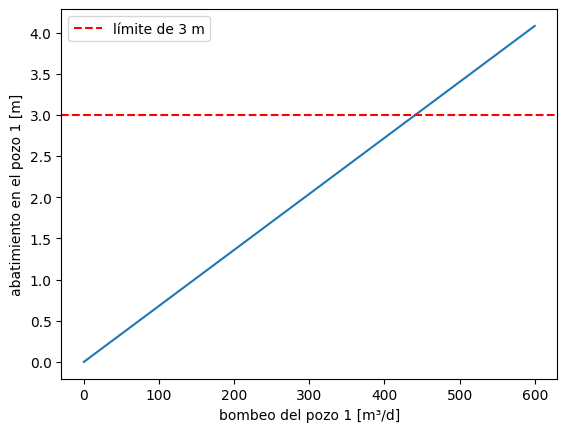

In [13]:
# Una gráfica: el abatimiento del pozo 1 crece en línea recta con su bombeo.
import matplotlib.pyplot as plt                  # la librería de gráficas; plt es su nombre corto

bombeo_p1 = np.linspace(0, 600, 50)              # 50 valores entre 0 y 600
abatimiento_p1 = alpha[0, 0] * bombeo_p1         # una recta

plt.plot(bombeo_p1, abatimiento_p1)              # la recta: x = bombeo, y = abatimiento
plt.axhline(3.0, color="red", linestyle="--", label="límite de 3 m")   # línea horizontal en el límite
plt.xlabel("bombeo del pozo 1 [m³/d]"); plt.ylabel("abatimiento en el pozo 1 [m]")
plt.legend(); plt.show()                         # la leyenda y mostrar la figura

✏️ **Inténtalo:** lee en la gráfica a partir de qué bombeo se cruza el límite de 3 m. Luego compruébalo con una línea de código: `3.0 / alpha[0, 0]`.

Con esto basta **para hoy**: el resto de este cuaderno usa únicamente estas seis cosas. El Apéndice A, al final del cuaderno, trae lo que necesitarás
en las sesiones 2 a 4. **En clase la saltamos**; hazla en casa antes del martes 10 (unos 25 minutos).

<div style="border-left: 5px solid #0B5B72; padding: 6px 12px; background: rgba(127,127,127,0.08);">✔ <b>Punto de control.</b> <code>alpha @ p</code> te dio tres abatimientos y la última celda dibujó la recta del abatimiento contra el bombeo. → Siguiente: <a href="#s3">3 · El problema y el simulador</a></div>

<div style="background:#C08A0B; color:white; padding:14px 18px; border-radius:6px; margin-top:36px;"><span style="font-size:1.4em; font-weight:bold;">PARTE II · El problema de Fritz</span><br><span style="opacity:0.9;">secciones 3 a 8 · 🏫 en clase · 40 min</span></div>

<hr style="border: none; border-top: 4px solid #C08A0B; margin: 28px 0 4px 0;">
<p style="color:#C08A0B; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 3 · EL PROBLEMA Y EL SIMULADOR</p>

<a id="s3"></a>

## 3 · El problema de Fritz Wasser y el simulador del curso (7 min)

<span style="color:#C08A0B">**⏱ 7 min · 🏫 en clase · Al terminar sabrás qué quiere Fritz, cuáles son sus tres reglas y cómo preguntarle a `hidra`.**</span>

Fritz Wasser tiene una finca sobre un **acuífero confinado**. Tiene tres pozos y quiere saber **cuánta agua puede bombear en total,
de forma constante**, sin romper tres reglas:

1. En ningún pozo el nivel puede bajar más de **3 m** (abatimiento máximo), o las bombas cavitan.
2. En el **humedal** que hay entre los pozos el nivel no puede bajar más de **1.25 m**, por una condición ambiental.
3. El **pozo 3** ya tiene un contrato: bombea exactamente **300 m³/d**, ni más ni menos.

Además, ninguna bomba da más de 1 000 m³/d y nadie inyecta agua (los bombeos no son negativos).

### 3.1 La historia y la formulación

Llamemos $p_1, p_2, p_3$ a los bombeos [m³/d] y $s_1, s_2, s_3, s_h$ a los abatimientos [m] en los pozos y en el humedal.

$$\max_{p_1,\,p_2}\; Z = p_1 + p_2 + p_3$$
$$\text{sujeto a:}\quad s_1 \le 3,\quad s_2 \le 3,\quad s_3 \le 3,\quad s_h \le 1.25,\quad p_3 = 300,\quad 0 \le p_1, p_2 \le 1000$$

Fíjate en algo importante: **los abatimientos no son variables que elijamos**. Son la respuesta del acuífero a los bombeos.
¿Quién nos dice cuánto vale $s_1$ si bombeamos $p$? **Un simulador.**

### 3.2 El simulador del curso

`hidra` es el acuífero de Fritz, construido con **rrwpt**, el modelo de flujo del laboratorio: resuelve la ecuación de flujo
en 8 281 nodos por elementos finitos. Hoy lo tratamos como una **caja negra**: le damos tres bombeos y nos devuelve el abatimiento
en todo el acuífero. Empecemos por mirarlo.

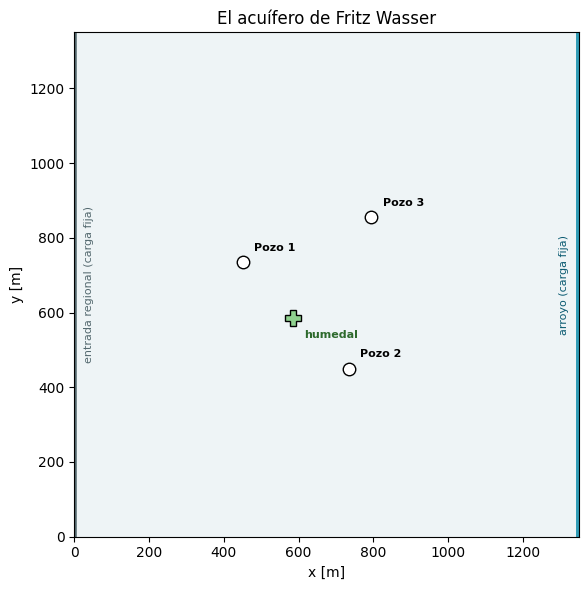

In [14]:
# El acuífero de Fritz: los tres pozos, el humedal y las fronteras.
hidra.mapa()
plt.show()

El agua entra por la izquierda (frontera de carga fija), cruza el dominio y sale por el **arroyo** de la derecha. Los pozos están en
el centro y el humedal entre los pozos 1 y 2.

Una corrida del simulador es una sola línea. Devuelve un objeto `Resultado` con todo lo que necesitamos.

Resultado(bombeos=[300.0, 300.0, 300.0] m³/d → abatimientos en pozos=[2.69, 2.75, 2.76] m, humedal=1.43 m)
abatimiento en los pozos [m]: [2.69 2.75 2.76]
abatimiento en el humedal [m]: 1.43


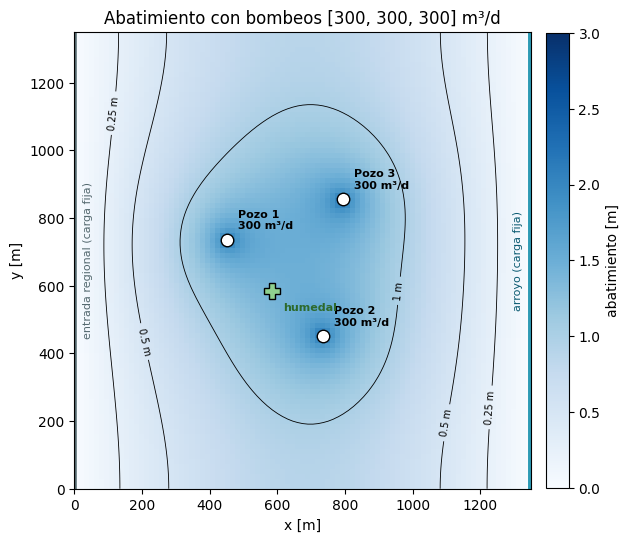

In [15]:
# Una corrida del simulador: se le dan los tres bombeos y devuelve un Resultado.
r = hidra.simular([300, 300, 300])     # p1, p2, p3 en m³/d
print(r)                               # el resumen del resultado
print("abatimiento en los pozos [m]:", np.round(r.abatimiento_pozos, 2))   # un arreglo de 3: uno por pozo
print("abatimiento en el humedal [m]:", round(r.abatimiento_humedal, 2))   # un solo número
hidra.mapa(r)                          # el cono de abatimiento de esta corrida
plt.show()

### 3.3 Qué es `hidra` y qué se le puede pedir

`hidra` es un **módulo de Python** (un archivo, `hidra.py`) escrito para este curso. Por dentro usa **rrwpt**, el modelo de flujo del
Laboratorio HIDRA (Rodríguez-Pretelín y Nowak, 2018): una malla de 90 × 90 celdas de 15 m, elementos finitos, acuífero confinado,
flujo estacionario. Por fuera, para ti, son unas cuantas funciones, cinco constantes y un objeto; las tres tablas siguientes son
**todo** lo que el cuaderno le pide. No necesitas saber nada más del simulador para todo el curso.

**Funciones** (se llaman con paréntesis):

| Qué | Para qué sirve | Devuelve |
|---|---|---|
| `hidra.verificar_entorno()` | Imprime las versiones y hace una corrida de prueba (la primera celda del cuaderno) | un mensaje que termina en `ENTORNO LISTO` |
| `hidra.simular([p1, p2, p3])` | Una corrida con esos bombeos en m³/d | un `Resultado` |
| `hidra.mapa()` / `hidra.mapa(r)` | Dibuja el acuífero, o el cono de abatimiento de un resultado `r` | una figura |
| `hidra.pozos_xy()` | Dónde están los tres pozos, en metros | lista de 3 pares (x, y): (450, 735), (735, 450), (795, 855) |
| `hidra.humedal_xy()` | Dónde está el humedal, en metros | un par (x, y): (585, 585) |
| `hidra.matriz_respuesta()` | La matriz 3 × 3 de coeficientes de respuesta en los pozos (hoy la fabricaremos a mano) | un arreglo 3 × 3 |
| `hidra.coeficientes_humedal()` | La fila del humedal: cuánto lo baja cada pozo por cada m³/d | un arreglo de 3 |
| `hidra.graficar_region_factible(A, b, nombres, ...)` | Dibuja restricciones lineales en el plano $(p_1, p_2)$ | una figura |

**Constantes** del problema (sin paréntesis), para no escribir números sueltos:

| Constante | Valor | Qué es |
|---|---|---|
| `hidra.S_MAX` | 3 m | Abatimiento máximo permitido en cada pozo |
| `hidra.S_MAX_HUMEDAL` | 1.25 m | Abatimiento máximo permitido en el humedal |
| `hidra.P3_COMPROMETIDO` | 300 m³/d | Bombeo fijo del pozo 3 (el contrato) |
| `hidra.P_MAX` | 1 000 m³/d | Capacidad de cada bomba: cota superior de cualquier bombeo |
| `hidra.LADO` | 1 350 m | Lado del dominio cuadrado (90 celdas de 15 m) |

Lo que devuelve `simular` es un objeto `Resultado`. Se lee con un punto: `r.algo`.

**Atributos** de un resultado `r`:

| Atributo de `r` | Qué contiene |
|---|---|
| `r.bombeos` | Los tres bombeos que pediste |
| `r.abatimiento_pozos` | Arreglo de 3 abatimientos [m], uno por pozo |
| `r.abatimiento_humedal` | Abatimiento [m] en el humedal |
| `r.abatimiento_maximo` | El mayor abatimiento de todo el acuífero [m] |
| `r.campo` | **Matriz 91 × 91** con el abatimiento en cada nodo (fila = y, columna = x) |
| `r.en(x, y)` | Abatimiento [m] en el punto (x, y) en metros, el que tú quieras (este lleva paréntesis: es una función del resultado) |

Tres ejemplos de uso:

In [16]:
# Tres cosas que se le pueden preguntar a un resultado y a hidra.
r = hidra.simular([200, 500, 300])

# 1) ¿cuánto baja el nivel en un punto cualquiera? Por ejemplo, en el centro del dominio y junto al arroyo
print("en el centro (675, 675):", round(r.en(675, 675), 3), "m")
print("junto al arroyo (1300, 675):", round(r.en(1300, 675), 3), "m   (casi cero: la carga está fija ahí)")

# 2) el campo completo es una matriz: podemos preguntarle cosas con NumPy
print("campo:", r.campo.shape, "| abatimiento máximo del acuífero:", round(r.campo.max(), 3), "m")
print("¿cuántos nodos tienen más de 1 m de abatimiento?", (r.campo > 1.0).sum(), "de", r.campo.size)   # True cuenta como 1 al sumar

# 3) dónde están los pozos y el humedal, en metros
print("pozos (x, y):", hidra.pozos_xy())
print("humedal (x, y):", hidra.humedal_xy())

en el centro (675, 675): 1.665 m
junto al arroyo (1300, 675): 0.132 m   (casi cero: la carga está fija ahí)
campo: (91, 91) | abatimiento máximo del acuífero: 4.063 m
¿cuántos nodos tienen más de 1 m de abatimiento? 2878 de 8281
pozos (x, y): [(450.0, 735.0), (735.0, 450.0), (795.0, 855.0)]
humedal (x, y): (585.0, 585.0)


Hay una opción más que usaremos en la Sesión 4: `hidra.simular(p, geologia=k)` con `k` de 0 a 9 corre el mismo problema sobre
una de diez geologías heterogéneas distintas. Hoy no la necesitamos; el acuífero de hoy es el homogéneo equivalente.

✏️ **Inténtalo:** pide `r.en(...)` en las coordenadas del pozo 1, `(450, 735)`, y compara con `r.abatimiento_pozos[0]`. Deben coincidir.

<div style="border-left: 5px solid #C08A0B; padding: 6px 12px; background: rgba(127,127,127,0.08);">✔ <b>Punto de control.</b> <code>hidra.simular([300, 300, 300])</code> dio <b>1.43 m</b> en el humedal (más que el límite de 1.25 m) y viste el mapa del cono. → Siguiente: <a href="#s4">4 · Los cinco conceptos, con hidra</a></div>

<hr style="border: none; border-top: 4px solid #C08A0B; margin: 28px 0 4px 0;">
<p style="color:#C08A0B; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 4 · LOS CINCO CONCEPTOS</p>

<a id="s4"></a>

## 4 · Los cinco conceptos, con hidra (7 min)

<span style="color:#C08A0B">**⏱ 7 min · 🏫 en clase · Al terminar verás las cinco palabras de la teoría sobre el acuífero de Fritz.**</span>

En la teoría vimos cinco palabras: **variables de decisión, función objetivo, restricciones, región factible y óptimo global**.
Vamos a verlas sobre el acuífero de Fritz, con tres decisiones de ejemplo que llamaremos A, B y C.

### 4.1 Variables de decisión

Lo que elegimos son los bombeos. Cambiar la decisión cambia el acuífero entero:

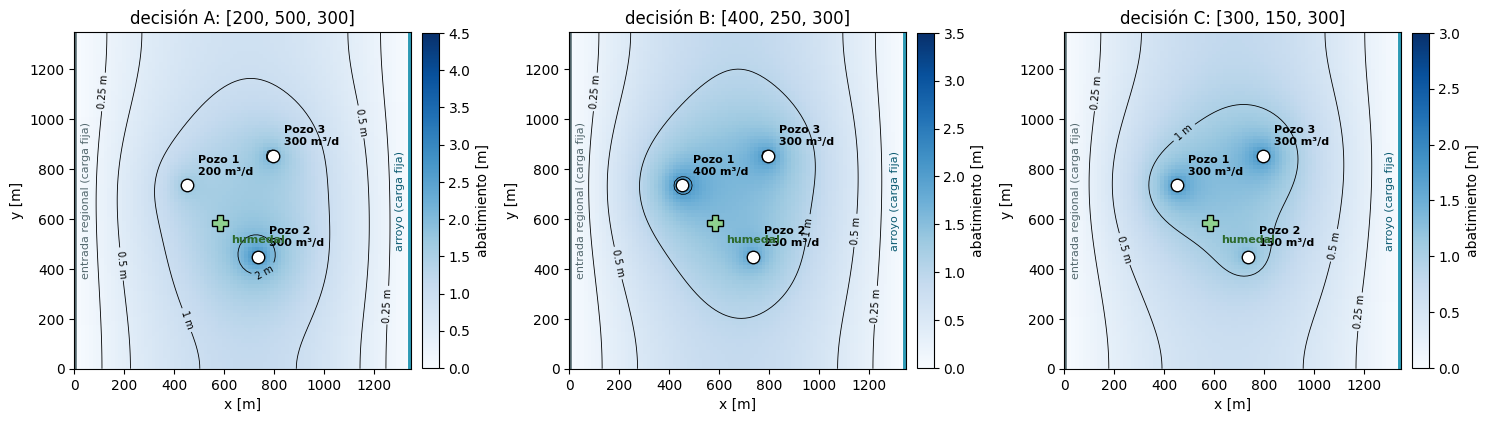

In [17]:
# Tres decisiones (A, B y C) en el mismo acuífero: simular cada una y dibujar su cono de abatimiento.
p_A = [200, 500, 300]                    # bombeos (p1, p2, p3) de la decisión A, en m³/d
p_B = [400, 250, 300]                    # decisión B
p_C = [300, 150, 300]                    # decisión C

r_A = hidra.simular(p_A)                 # una corrida del simulador por decisión
r_B = hidra.simular(p_B)
r_C = hidra.simular(p_C)

fig, axs = plt.subplots(1, 3, figsize=(15, 5))          # una figura con 3 paneles: axs[0], axs[1] y axs[2]
hidra.mapa(r_A, ax=axs[0], titulo=f"decisión A: {p_A}")   # cada cono en su panel
hidra.mapa(r_B, ax=axs[1], titulo=f"decisión B: {p_B}")
hidra.mapa(r_C, ax=axs[2], titulo=f"decisión C: {p_C}")
plt.tight_layout()                                       # acomodar los paneles
plt.savefig("Información/figuras/conceptos_variables.png", dpi=150)
plt.show()

decisiones = {"A": p_A, "B": p_B, "C": p_C}             # las guardamos con su nombre, para las celdas siguientes
resultados = {"A": r_A, "B": r_B, "C": r_C}

### 4.2 Función objetivo y restricciones

Lo que queremos maximizar: el bombeo total $Z = p_1 + p_2 + p_3$. Y **restricciones**: las reglas que cada decisión respeta o rompe.

In [18]:
# Para cada decisión: el objetivo Z (bombeo total), los abatimientos y si cumple las reglas.
for nombre in ["A", "B", "C"]:
    p = decisiones[nombre]                                   # sus bombeos
    r = resultados[nombre]                                   # su corrida (ya la hicimos en la celda anterior)
    Z = sum(p)                                               # el objetivo: el bombeo total
    cumple_pozos = r.abatimiento_pozos.max() <= hidra.S_MAX  # el pozo que más baja, ¿se queda en 3 m o menos?
    cumple_humedal = r.abatimiento_humedal <= hidra.S_MAX_HUMEDAL   # ¿el humedal se queda en 1.25 m o menos?
    print("decisión", nombre, "| Z =", Z, "m³/d",
          "| s pozos =", np.round(r.abatimiento_pozos, 2), "m",
          "| s humedal =", round(r.abatimiento_humedal, 2), "m",
          "| factible:", cumple_pozos and cumple_humedal)

decisión A | Z = 1000 m³/d | s pozos = [2.22 4.06 2.85] m | s humedal = 1.63 m | factible: False
decisión B | Z = 950 m³/d | s pozos = [3.32 2.5  2.82] m | s humedal = 1.51 m | factible: False
decisión C | Z = 750 m³/d | s pozos = [2.53 1.69 2.6 ] m | s humedal = 1.15 m | factible: True


A y B bombean más que C, pero rompen alguna regla (el pozo 2 en A, el pozo 1 y el humedal en B). C respeta todas... pero ¿es la mejor? Para responder hay que ver **todas** las
decisiones a la vez.

### 4.3 Región factible

Con el pozo 3 fijo, cada decisión es un punto del plano $(p_1, p_2)$. `hidra` ya sabe fabricar la matriz de
respuesta (en la sección 6 lo haremos nosotros a mano); con ella, cada restricción es una recta y la región factible es el polígono
que queda dentro de todas:

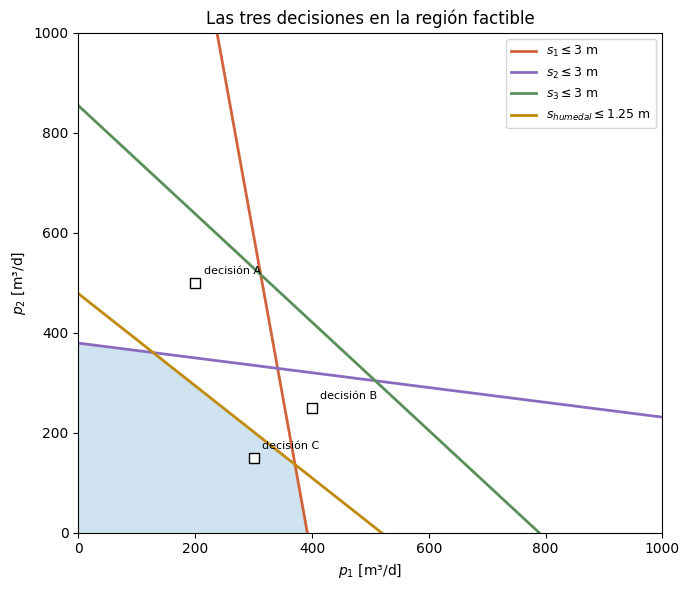

In [19]:
# La región factible: las cuatro reglas como rectas en el plano (p1, p2), con p3 fijo en 300, y las tres decisiones encima.
alpha = hidra.matriz_respuesta()              # en la sección 6 la fabricaremos nosotros
alpha_humedal = hidra.coeficientes_humedal()  # la fila del humedal: cuánto lo baja cada pozo por cada m³/d
p3 = hidra.P3_COMPROMETIDO                    # 300 m³/d: el pozo 3 no se decide

# A: una fila por regla (pozo 1, pozo 2, pozo 3, humedal) y una columna por bombeo que se decide (p1, p2)
A_todas = np.array([[alpha[0, 0], alpha[0, 1]],
                    [alpha[1, 0], alpha[1, 1]],
                    [alpha[2, 0], alpha[2, 1]],
                    [alpha_humedal[0], alpha_humedal[1]]])

# b: cada límite menos lo que ya baja por el pozo 3 (su columna de alpha por 300)
b_todas = np.array([hidra.S_MAX - alpha[0, 2] * p3,
                    hidra.S_MAX - alpha[1, 2] * p3,
                    hidra.S_MAX - alpha[2, 2] * p3,
                    hidra.S_MAX_HUMEDAL - alpha_humedal[2] * p3])

nombres = ["$s_1 \\leq 3$ m", "$s_2 \\leq 3$ m", "$s_3 \\leq 3$ m", "$s_{humedal} \\leq 1.25$ m"]   # el nombre de cada recta
puntos = [((200, 500), "decisión A"), ((400, 250), "decisión B"), ((300, 150), "decisión C")]     # (p1, p2) de cada decisión
hidra.graficar_region_factible(A_todas, b_todas, nombres, puntos=puntos, titulo="Las tres decisiones en la región factible")
plt.savefig("Información/figuras/conceptos_region.png", dpi=150)
plt.show()

C cae dentro del polígono; A y B, fuera.

### 4.4 Óptimo global

El **óptimo global** es el punto del polígono con la mayor $p_1 + p_2$. Lo encontraremos
con certificado en la sección 7, y verás que está en una esquina: es la quinta palabra y la razón de ser de esta sesión.

<div style="border-left: 5px solid #C08A0B; padding: 6px 12px; background: rgba(127,127,127,0.08);">✔ <b>Punto de control.</b> la tabla dice que C es factible y que A y B no, y la región factible está dibujada con las tres decisiones. → Siguiente: <a href="#s5">5 · Prueba y error</a></div>

<hr style="border: none; border-top: 4px solid #C08A0B; margin: 28px 0 4px 0;">
<p style="color:#C08A0B; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 5 · PRUEBA Y ERROR</p>

<a id="s5"></a>

## 5 · Prueba y error (4 min)

<span style="color:#C08A0B">**⏱ 4 min · 🏫 en clase · Al terminar tendrás tu mejor marca a mano, sin ningún método.**</span>

Antes de usar ningún método, hagamos lo que haría cualquiera: **probar**. La siguiente función corre el simulador y dice si
una propuesta de bombeos respeta las reglas.

In [20]:
# evaluar(p1, p2): simula una decisión (con p3 = 300), dice si cumple las reglas y la guarda en INTENTOS.
INTENTOS = []                                    # tus intentos (ojo: si vuelves a ejecutar esta celda, la lista empieza vacía)

def evaluar(p1, p2, con_humedal=True):
    r = hidra.simular([p1, p2, hidra.P3_COMPROMETIDO])   # una corrida con tu decisión
    s = r.abatimiento_pozos                      # abatimiento en los 3 pozos
    tol = 1e-6                                   # tolerancia numérica: 3.0000000001 m cuenta como 3 m
    cumple_pozos = s.max() <= hidra.S_MAX + tol  # el pozo que más baja, ¿se queda en 3 m?
    cumple_humedal = r.abatimiento_humedal <= hidra.S_MAX_HUMEDAL + tol
    if not con_humedal:                          # en la sección 7 todavía no se pide la regla del humedal
        cumple_humedal = True
    factible = cumple_pozos and cumple_humedal
    if con_humedal:
        INTENTOS.append((p1, p2, factible))      # se guarda (p1, p2, ¿factible?) para dibujarlo después
    total = p1 + p2 + hidra.P3_COMPROMETIDO
    print("p1 =", round(p1, 2), "| p2 =", round(p2, 2), "| p3 = 300 | total", round(total, 2), "m³/d",
          "| s pozos =", np.round(s, 2), "| s humedal =", round(r.abatimiento_humedal, 2), "| factible:", factible)

evaluar(300, 300)                                # tres decisiones de ejemplo; después escribe las tuyas
evaluar(400, 400)
evaluar(300, 150)

p1 = 300 | p2 = 300 | p3 = 300 | total 900.0 m³/d | s pozos = [2.69 2.75 2.76] | s humedal = 1.43 | factible: False
p1 = 400 | p2 = 400 | p3 = 300 | total 1100.0 m³/d | s pozos = [3.47 3.57 2.98] | s humedal = 1.78 | factible: False
p1 = 300 | p2 = 150 | p3 = 300 | total 750.0 m³/d | s pozos = [2.53 1.69 2.6 ] | s humedal = 1.15 | factible: True


Fíjate: 300 y 300 ya rompe la regla del humedal aunque los pozos estén bien. Con 300 y 150 todo se cumple, pero el total es menor.

✏️ **Inténtalo (3 minutos):** cambia los números y busca **el mayor total factible** que puedas. Anota tu mejor marca.

Luego piensa: ¿cuántas combinaciones de $(p_1, p_2)$ existen? Infinitas. ¿Cómo sabes que tu mejor marca es *la mejor*? No lo sabes.
Eso es exactamente lo que resuelve la optimización: **encontrar la mejor y demostrar que lo es**.

Cada vez que llamas a `evaluar`, tu intento queda guardado. Así se ven:

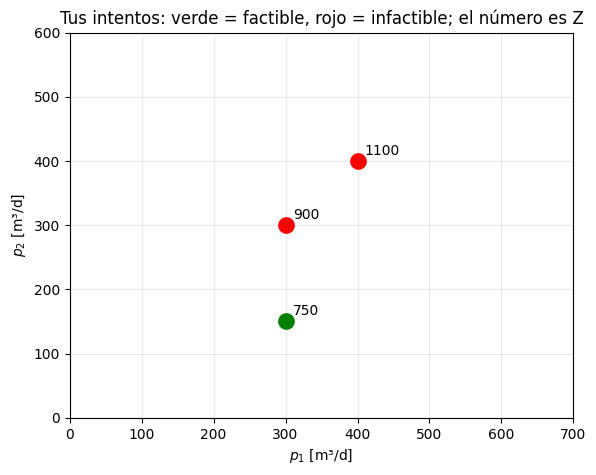

In [21]:
# Tus intentos en el plano (p1, p2): verde si fue factible, rojo si no; el número es el total Z.
MIS_INTENTOS = list(INTENTOS)                    # una copia: la usaremos en la sección 8
fig, ax = plt.subplots(figsize=(6.5, 5))
for p1_, p2_, ok in MIS_INTENTOS:                # cada intento trae (p1, p2, ¿factible?)
    if ok:
        color = "green"
    else:
        color = "red"
    ax.plot(p1_, p2_, "o", ms=11, color=color)   # el punto
    Z = p1_ + p2_ + hidra.P3_COMPROMETIDO
    ax.text(p1_ + 10, p2_ + 10, round(Z))        # su total Z, un poco arriba a la derecha
ax.set_xlim(0, 700)
ax.set_ylim(0, 600)
ax.set_xlabel("$p_1$ [m³/d]")
ax.set_ylabel("$p_2$ [m³/d]")
ax.set_title("Tus intentos: verde = factible, rojo = infactible; el número es Z")
ax.grid(alpha=0.3)
plt.show()

Los verdes y los rojos están separados por una **frontera** que todavía no vemos. En la sección 8 la dibujaremos encima de tus intentos.

<div style="border-left: 5px solid #C08A0B; padding: 6px 12px; background: rgba(127,127,127,0.08);">✔ <b>Punto de control.</b> tienes tu mejor marca guardada; la volverás a ver en la sección 8. → Siguiente: <a href="#s6">6 · La matriz de respuesta</a></div>

<hr style="border: none; border-top: 4px solid #C08A0B; margin: 28px 0 4px 0;">
<p style="color:#C08A0B; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 6 · LA MATRIZ DE RESPUESTA</p>

<a id="s6"></a>

## 6 · El simulador cabe en 12 números: la matriz de respuesta (8 min)

<span style="color:#C08A0B">**⏱ 8 min · 🏫 en clase · Al terminar habrás fabricado la matriz de respuesta y comprobado que el acuífero es lineal.**</span>

El acuífero de Fritz es confinado y el flujo es estacionario. Eso tiene una consecuencia matemática enorme: la ecuación de flujo
es **lineal**, y por tanto vale el **principio de superposición**: el abatimiento que producen tres pozos juntos es la **suma** de
los que produce cada uno por separado, y el de un pozo es **proporcional** a su bombeo.

Entonces basta con tres corridas, una por pozo con bombeo unitario de 1 m³/d, para saber cuánto abate cada pozo en cada punto.
A esos números se les llama **coeficientes de respuesta** $\alpha_{ij}$: abatimiento en el punto $i$ por cada m³/d bombeado en el pozo $j$.

Vamos a **fabricar** la matriz con el simulador, usando un ciclo `for`:

In [22]:
# Fabricar la matriz de respuesta con tres corridas del simulador.
# En cada corrida bombea UN solo pozo, con 1 m³/d; los otros dos están apagados.
# Lo que baja cada punto en esa corrida es «cuánto lo baja ese pozo por cada m³/d».

r_pozo1 = hidra.simular([1, 0, 0])       # corrida 1: solo bombea el pozo 1
r_pozo2 = hidra.simular([0, 1, 0])       # corrida 2: solo bombea el pozo 2
r_pozo3 = hidra.simular([0, 0, 1])       # corrida 3: solo bombea el pozo 3

np.set_printoptions(precision=6, suppress=True)   # mostrar 6 decimales, sin notación científica

# Lo que dice cada corrida: cuánto bajan los tres pozos y el humedal
print("corrida 1 (solo el pozo 1): pozos", r_pozo1.abatimiento_pozos, "| humedal", round(r_pozo1.abatimiento_humedal, 6))
print("corrida 2 (solo el pozo 2): pozos", r_pozo2.abatimiento_pozos, "| humedal", round(r_pozo2.abatimiento_humedal, 6))
print("corrida 3 (solo el pozo 3): pozos", r_pozo3.abatimiento_pozos, "| humedal", round(r_pozo3.abatimiento_humedal, 6))

# Cada corrida es una COLUMNA de alpha: se ponen una junto a otra (column_stack = apilar como columnas)
alpha = np.column_stack([r_pozo1.abatimiento_pozos,      # columna 1: lo que provoca el pozo 1
                         r_pozo2.abatimiento_pozos,      # columna 2: lo que provoca el pozo 2
                         r_pozo3.abatimiento_pozos])     # columna 3: lo que provoca el pozo 3

# La fila del humedal: un número de cada corrida
alpha_humedal = np.array([r_pozo1.abatimiento_humedal,
                          r_pozo2.abatimiento_humedal,
                          r_pozo3.abatimiento_humedal])

print("\nalpha [m por m³/d]  (fila = dónde se mide, columna = qué pozo bombea):\n", alpha)
print("fila del humedal:", alpha_humedal)

corrida 1 (solo el pozo 1): pozos [0.006775 0.001047 0.001147] | humedal 0.001692
corrida 2 (solo el pozo 2): pozos [0.001047 0.007071 0.001059] | humedal 0.001836
corrida 3 (solo el pozo 3): pozos [0.001147 0.001059 0.006983] | humedal 0.001239

alpha [m por m³/d]  (fila = dónde se mide, columna = qué pozo bombea):
 [[0.006775 0.001047 0.001147]
 [0.001047 0.007071 0.001059]
 [0.001147 0.001059 0.006983]]
fila del humedal: [0.001692 0.001836 0.001239]


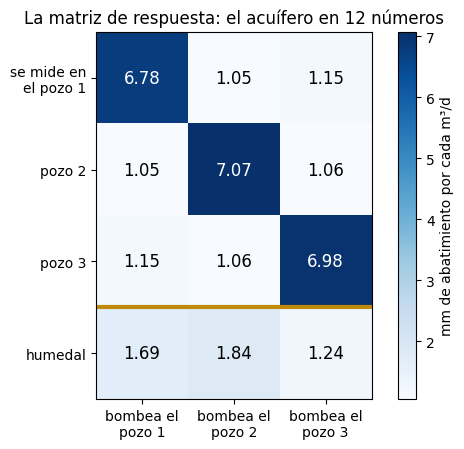

In [23]:
# La matriz de respuesta como tabla de colores: cuanto más oscuro, más abatimiento por cada m³/d.
M = np.vstack([alpha, alpha_humedal]) * 1000     # en milímetros por m³/d, para leerla mejor
fig, ax = plt.subplots(figsize=(5.6, 4.6))
im = ax.imshow(M, cmap="Blues")                  # cada celda de la matriz, pintada según su valor
for i in range(4):                               # renglones: pozo 1, 2, 3 y humedal
    for j in range(3):                           # columnas: el pozo que bombea
        ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=12, color="white" if M[i, j] > 4 else "black")   # el número encima (blanco si el fondo es oscuro)
ax.set_xticks(range(3), ["bombea el\npozo 1", "bombea el\npozo 2", "bombea el\npozo 3"])
ax.set_yticks(range(4), ["se mide en\nel pozo 1", "pozo 2", "pozo 3", "humedal"])
ax.axhline(2.5, color="#c08a0b", lw=3)           # una raya que separa los pozos del humedal
fig.colorbar(im, label="mm de abatimiento por cada m³/d")
ax.set_title("La matriz de respuesta: el acuífero en 12 números"); plt.tight_layout(); plt.show()

Lee la matriz: la diagonal (cada pozo sobre sí mismo) es grande, unos 0.007 m por m³/d; fuera de la diagonal (cada pozo sobre
los demás) es siete veces menor. Y es **simétrica**: el pozo 1 afecta al 2 igual que el 2 al 1.

Ahora la prueba de fuego. Si la superposición es cierta, para cualquier $p$ debe cumplirse $s = \alpha \, p$. Comparemos el
simulador completo contra la multiplicación de matriz:

In [24]:
# Comprobación: la matriz da lo mismo que el simulador completo para un bombeo cualquiera.
p = np.array([250, 400, 300])
s_simulador = hidra.simular(p).abatimiento_pozos   # la corrida completa (8 281 nodos)
s_matriz = alpha @ p                               # la matriz por los bombeos (12 números)

print("simulador:", np.round(s_simulador, 4))
print("alpha @ p :", np.round(s_matriz, 4))
print("diferencia máxima:", np.abs(s_simulador - s_matriz).max())   # del orden de 1e-12: cero numérico

simulador: [2.457  3.4083 2.8054]
alpha @ p : [2.457  3.4083 2.8054]
diferencia máxima: 1.1550760348200129e-12


La superposición no vale solo en los tres pozos: vale en **todo el acuífero**. Simulemos cada pozo solo, sumemos los tres mapas y comparemos
con la corrida de los tres juntos.

diferencia máxima entre la suma y la corrida conjunta, en los 8 281 nodos: 2.130018383894594e-12 m


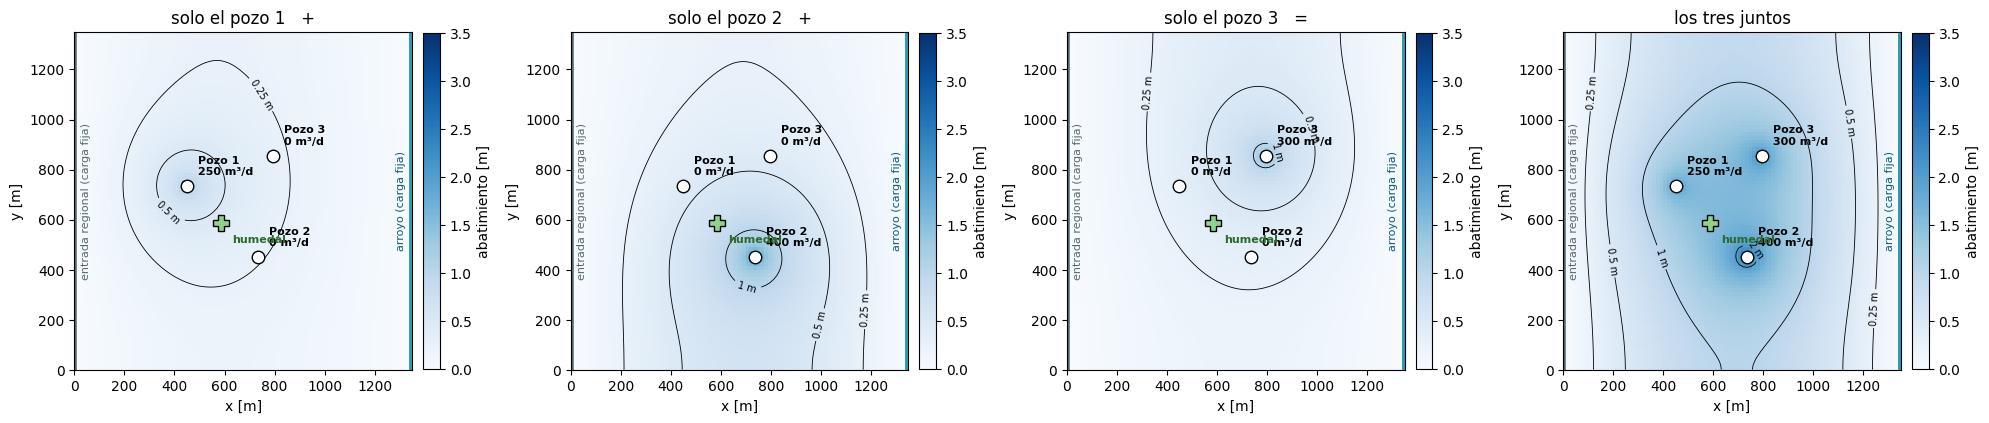

In [25]:
# La superposición, en mapas: cada pozo solo, y los tres juntos, que son exactamente la suma de los tres primeros.
r1 = hidra.simular([p[0], 0, 0])                 # solo el pozo 1
r2 = hidra.simular([0, p[1], 0])                 # solo el pozo 2
r3 = hidra.simular([0, 0, p[2]])                 # solo el pozo 3
juntos = hidra.simular(p)                        # los tres a la vez

suma = r1.campo + r2.campo + r3.campo            # sumar los tres mapas, nodo por nodo
print("diferencia máxima entre la suma y la corrida conjunta, en los 8 281 nodos:", np.abs(suma - juntos.campo).max(), "m")

tope = 3.5                                       # la misma escala de color en los cuatro mapas (0 a 3.5 m), para poder compararlos
fig, axs = plt.subplots(1, 4, figsize=(20, 5))   # cuatro paneles en un renglón
hidra.mapa(r1, ax=axs[0], titulo="solo el pozo 1   +", vmax=tope)
hidra.mapa(r2, ax=axs[1], titulo="solo el pozo 2   +", vmax=tope)
hidra.mapa(r3, ax=axs[2], titulo="solo el pozo 3   =", vmax=tope)
hidra.mapa(juntos, ax=axs[3], titulo="los tres juntos", vmax=tope)
plt.tight_layout()
plt.show()

La diferencia es del orden de $10^{-12}$: cero numérico. **El simulador de 8 281 nodos cabe en 12 números** (9 de los pozos y 3 del humedal).
Esto es lo que convierte un problema de simulación en un problema de **programación lineal**, que sí sabemos resolver con garantía.

✏️ **Inténtalo:** cambia `p` por otros tres valores. ¿Sigue dando cero la diferencia? ¿Y si pones un bombeo de 5 000 m³/d? (Físicamente
absurdo, pero el modelo es lineal: la diferencia seguirá siendo cero. Esa es la limitación del modelo confinado, y la aceptamos hoy a propósito.)

<div style="border-left: 5px solid #C08A0B; padding: 6px 12px; background: rgba(127,127,127,0.08);">✔ <b>Punto de control.</b> <code>simular(p)</code> y <code>alpha @ p</code> coinciden: la diferencia es del orden de 1e-12 m. → Siguiente: <a href="#s7">7 · La solución exacta</a></div>

<hr style="border: none; border-top: 4px solid #C08A0B; margin: 28px 0 4px 0;">
<p style="color:#C08A0B; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 7 · SOLUCIÓN EXACTA</p>

<a id="s7"></a>

## 7 · Solución exacta con programación lineal (8 min)

<span style="color:#C08A0B">**⏱ 8 min · 🏫 en clase · Al terminar tendrás el óptimo exacto, con garantía, y su lugar en la región factible.**</span>

Con $p_3 = 300$ fijo, el problema queda en **dos variables**, $p_1$ y $p_2$. Cada restricción $s_i \le s_{\max}$ se escribe
$\alpha_{i1} p_1 + \alpha_{i2} p_2 \le s_{\max} - \alpha_{i3} \cdot 300$: una recta en el plano $(p_1, p_2)$.

SciPy trae un resolvedor de programación lineal, `linprog`, que pide el problema en **forma estándar**:

$$\min\; c^\top x \qquad \text{s.a.}\qquad A_{ub}\, x \le b_{ub}, \qquad x_{\min} \le x \le x_{\max}$$

Dos detalles de traducción. `linprog` **minimiza**, y nosotros queremos maximizar $p_1 + p_2$: por eso $c = [-1, -1]$ (minimizar
$-Z$ es maximizar $Z$). Y la demanda fija del pozo 3 se pasa al lado derecho. Primero resolvamos **sin el humedal**, como en el ejemplo clásico:

In [26]:
# El óptimo exacto con linprog (todavía sin la regla del humedal).
from scipy.optimize import linprog

p3 = hidra.P3_COMPROMETIDO                          # 300 m³/d: el pozo 3 no se decide

# Las reglas A·x ≤ b, una fila por pozo (como en la lámina 34, todavía sin el humedal)
A_pozos = np.array([[alpha[0, 0], alpha[0, 1]],     # pozo 1: cuánto lo bajan p1 y p2 por cada m³/d
                    [alpha[1, 0], alpha[1, 1]],     # pozo 2
                    [alpha[2, 0], alpha[2, 1]]])    # pozo 3
b_pozos = np.array([hidra.S_MAX - alpha[0, 2] * p3, # pozo 1: sus 3 m menos lo que ya lo baja el pozo 3
                    hidra.S_MAX - alpha[1, 2] * p3, # pozo 2
                    hidra.S_MAX - alpha[2, 2] * p3])# pozo 3

# Lo demás que pide linprog
c = [-1, -1]                                        # linprog MINIMIZA: para maximizar p1 + p2 se le pide minimizar −p1 − p2
cotas = [(0, hidra.P_MAX), (0, hidra.P_MAX)]        # cada bombeo entre 0 y la capacidad de la bomba (1 000 m³/d)

sol = linprog(c, A_ub=A_pozos, b_ub=b_pozos, bounds=cotas)   # resolver
p1_opt = sol.x[0]                                   # sol.x trae los bombeos óptimos: primero p1...
p2_opt = sol.x[1]                                   # ...luego p2
Z_opt = p1_opt + p2_opt + p3                        # el bombeo total, sumando el pozo 3
print("Óptimo sin humedal:  p1* =", round(p1_opt, 2), "| p2* =", round(p2_opt, 2), "| p3 =", int(p3), " →  Z* =", round(Z_opt, 2), "m³/d")

Óptimo sin humedal:  p1* = 341.15 | p2* = 328.77 | p3 = 300  →  Z* = 969.92 m³/d


Comprobemos con el simulador que ese punto respeta las reglas de los pozos (el humedal entra en la sección 8), y veamos la geometría: la región factible es un polígono
y el óptimo está en una **esquina** (un vértice). Siempre es así en programación lineal, y es la razón de que exista garantía.

p1 = 341.15 | p2 = 328.77 | p3 = 300 | total 969.92 m³/d | s pozos = [3.   3.   2.83] | s humedal = 1.55 | factible: True


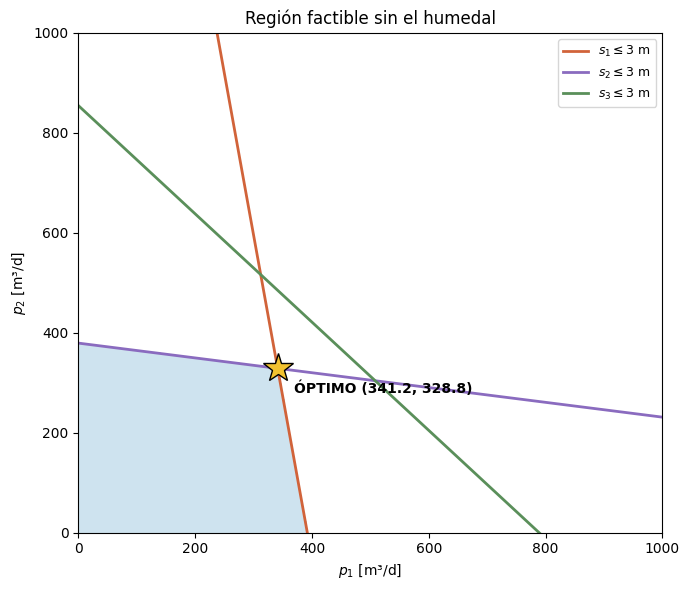

In [27]:
# Comprobar el óptimo con el simulador y verlo en la región factible.
evaluar(p1_opt, p2_opt, con_humedal=False)   # de momento, sin la regla del humedal

hidra.graficar_region_factible(A_pozos, b_pozos, ["$s_1 \\leq 3$ m", "$s_2 \\leq 3$ m", "$s_3 \\leq 3$ m"],
                               p_optimo=(p1_opt, p2_opt), titulo="Región factible sin el humedal")   # la estrella marca el óptimo
plt.savefig("Información/figuras/region_factible_pozos.png", dpi=150); plt.show()

Dos restricciones están **activas** (se cumplen con igualdad, $s_1 = s_2 = 3.00$ m) y la tercera tiene holgura. El óptimo es el vértice
donde se cruzan las dos rectas activas. Ese valor, **Z\* = 969.92 m³/d**, es la **verdad de referencia** del curso: el martes que viene un
enjambre de partículas intentará llegar a él sin usar la matriz.

Pero el humedal todavía no ha entrado. Mira el mapa del óptimo:

abatimiento en el humedal con ese óptimo: 1.55 m   (límite: 1.25 m)


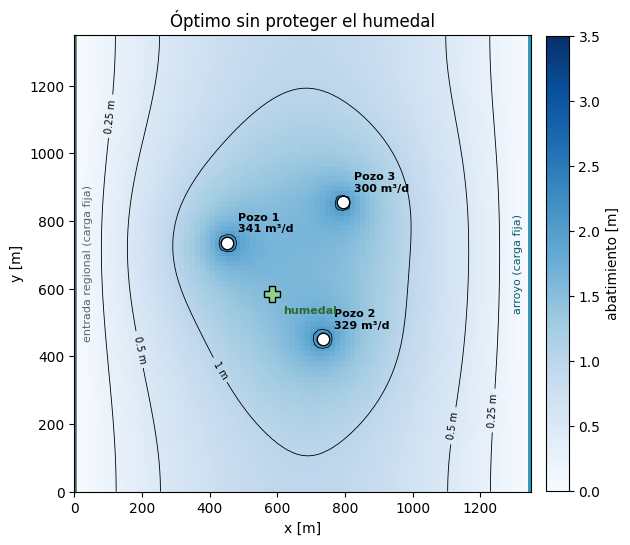

In [28]:
# ¿Y el humedal? Con ese óptimo, el humedal baja más de lo permitido.
r_opt = hidra.simular([p1_opt, p2_opt, p3])    # la corrida completa con el óptimo sin humedal
print("abatimiento en el humedal con ese óptimo:", round(r_opt.abatimiento_humedal, 2), "m   (límite:", hidra.S_MAX_HUMEDAL, "m)")
hidra.mapa(r_opt, titulo="Óptimo sin proteger el humedal")
plt.savefig("Información/figuras/mapa_optimo_pozos.png", dpi=150); plt.show()

<div style="border-left: 5px solid #C08A0B; padding: 6px 12px; background: rgba(127,127,127,0.08);">✔ <b>Punto de control.</b> <b>Z* = 969.92 m³/d</b> sin humedal, en un vértice de la región. → Siguiente: <a href="#s8">8 · El humedal</a></div>

<hr style="border: none; border-top: 4px solid #C08A0B; margin: 28px 0 4px 0;">
<p style="color:#C08A0B; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 8 · EL HUMEDAL</p>

<a id="s8"></a>

## 8 · La matriz es el campo: entra el humedal (6 min)

<span style="color:#C08A0B">**⏱ 6 min · 🏫 en clase · Al terminar sabrás agregar una regla nueva como una fila más y leer cuánto cuesta.**</span>

El óptimo anterior abate el humedal más de lo permitido. Con una tabla de tres pozos esto sería invisible. Con el simulador no:
tenemos el abatimiento en **todos** los nodos, y cualquier punto del acuífero puede convertirse en **una fila más** de la matriz.
Ya fabricamos esa fila en la sección 6 (`alpha_humedal`). Solo hay que apilarla:

In [29]:
# Agregar la regla del humedal: una fila más en A y un valor más en b, y resolver otra vez.
A_total = np.array([[alpha[0, 0], alpha[0, 1]],               # pozo 1
                    [alpha[1, 0], alpha[1, 1]],               # pozo 2
                    [alpha[2, 0], alpha[2, 1]],               # pozo 3
                    [alpha_humedal[0], alpha_humedal[1]]])    # la fila nueva: el humedal
b_total = np.array([b_pozos[0], b_pozos[1], b_pozos[2],      # los tres límites de antes...
                    hidra.S_MAX_HUMEDAL - alpha_humedal[2] * p3])   # ...y el del humedal: 1.25 m menos lo que ya lo baja el pozo 3

sol_h = linprog(c, A_ub=A_total, b_ub=b_total, bounds=cotas)  # lo mismo que antes, con una regla más
p1_h = sol_h.x[0]
p2_h = sol_h.x[1]
Z_h = p1_h + p2_h + p3
print("Óptimo con humedal:  p1* =", round(p1_h, 2), "| p2* =", round(p2_h, 2), "| p3 =", int(p3), " →  Z* =", round(Z_h, 2), "m³/d")
print("Proteger el humedal cuesta", round(Z_opt - Z_h, 1), "m³/d.")
print("El pozo 1 pasa de", round(p1_opt, 2), "a", round(p1_h, 2), "m³/d; el pozo 2, de", round(p2_opt, 2), "a", round(p2_h, 2), "m³/d: lo paga el pozo 2.")

evaluar(p1_h, p2_h)                    # comprobarlo con el simulador (y queda en tus intentos)

Óptimo con humedal:  p1* = 370.88 | p2* = 136.46 | p3 = 300  →  Z* = 807.34 m³/d
Proteger el humedal cuesta 162.6 m³/d.
El pozo 1 pasa de 341.15 a 370.88 m³/d; el pozo 2, de 328.77 a 136.46 m³/d: lo paga el pozo 2.
p1 = 370.88 | p2 = 136.46 | p3 = 300 | total 807.34 m³/d | s pozos = [3.   1.67 2.66] | s humedal = 1.25 | factible: True


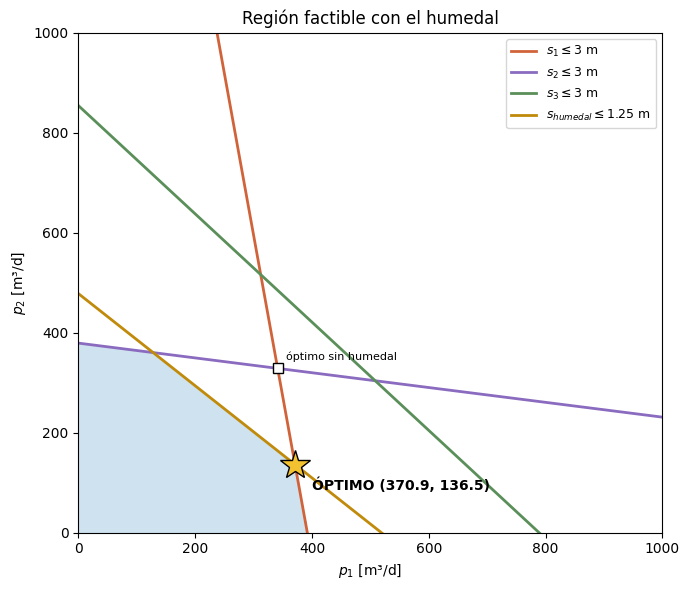

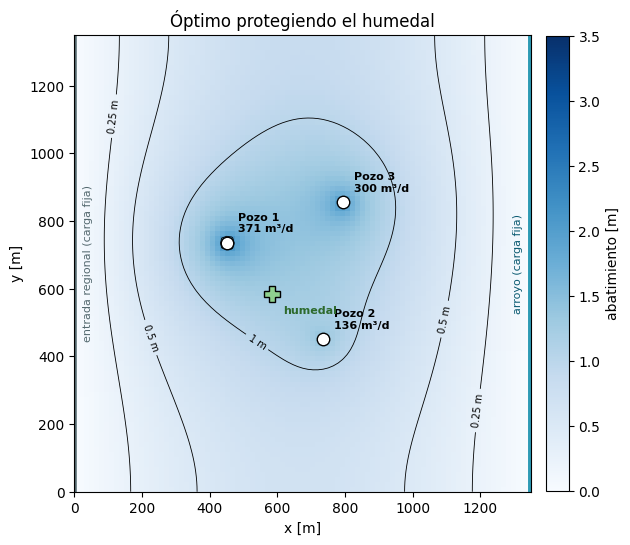

In [30]:
# La región con el humedal, y el mapa del nuevo óptimo.
hidra.graficar_region_factible(A_total, b_total,
                               ["$s_1 \\leq 3$ m", "$s_2 \\leq 3$ m", "$s_3 \\leq 3$ m", "$s_{humedal} \\leq 1.25$ m"],
                               p_optimo=(p1_h, p2_h), puntos=[((p1_opt, p2_opt), "óptimo sin humedal")],   # el óptimo viejo queda fuera
                               titulo="Región factible con el humedal")
plt.savefig("Información/figuras/region_factible_humedal.png", dpi=150); plt.show()

r_h = hidra.simular([p1_h, p2_h, p3])          # la corrida completa con el nuevo óptimo
hidra.mapa(r_h, titulo="Óptimo protegiendo el humedal")
plt.savefig("Información/figuras/mapa_optimo_humedal.png", dpi=150); plt.show()

Lee los dos mapas uno junto al otro. La curva de 1 m ya no toca el humedal, y la región factible perdió una esquina.
Ahora las restricciones activas son **el pozo 1 y el humedal**; el pozo 2 quedó con holgura. Esa es la lectura hidrogeológica
que Fritz necesita: *«puedes bombear 807 m³/d en total; si quieres más, el que estorba es el humedal, no tus bombas»*.

✏️ **Inténtalo:** cambia el límite del humedal, por ejemplo `hidra.S_MAX_HUMEDAL = 1.5` o `1.0`, vuelve a ejecutar desde la celda de
`A_total` y observa qué pasa con $Z^*$ y con el pozo 2. (Con 1.0 m el pozo 2 se apaga por completo.)

### 8.1 Tus intentos sobre la región factible

Ahora sí se ve la frontera: los intentos verdes cayeron dentro del polígono y los rojos fuera. Y el óptimo está en la esquina que nadie
encuentra a mano.

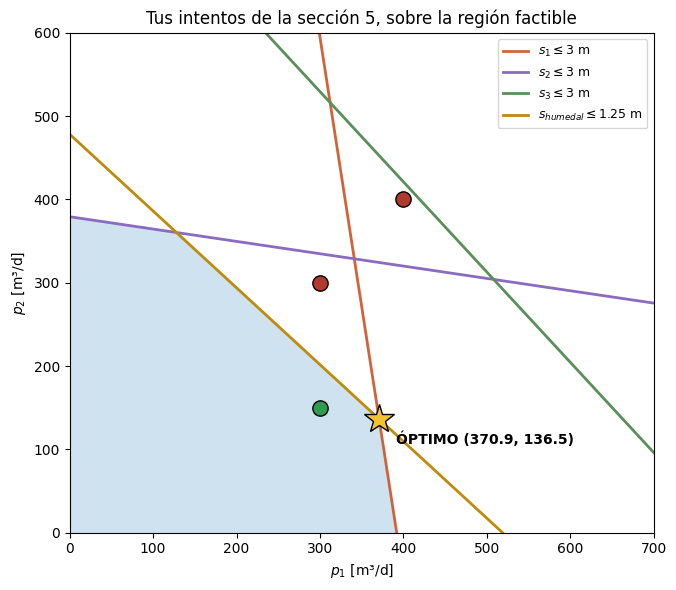

In [31]:
# Tus intentos de la sección 5, ahora sobre la región factible verdadera.
ax = hidra.graficar_region_factible(A_total, b_total,
                                    ["$s_1 \\leq 3$ m", "$s_2 \\leq 3$ m", "$s_3 \\leq 3$ m", "$s_{humedal} \\leq 1.25$ m"],
                                    p_optimo=(p1_h, p2_h), titulo="Tus intentos de la sección 5, sobre la región factible")   # devuelve el panel (ax) para dibujar encima
for p1_, p2_, ok in MIS_INTENTOS:
    ax.plot(p1_, p2_, "o", ms=11, mfc="#2e9b4f" if ok else "#B03A2E", mec="k", zorder=6)   # verde factible, rojo no (zorder: encima de todo)
ax.set_xlim(0, 700); ax.set_ylim(0, 600); plt.show()

### 8.2 El óptimo en corte: las dos reglas activas tocan su límite

**La pregunta.** En el óptimo, ¿qué reglas quedan *justo* en su límite? A esas se les llama **restricciones activas**: son las que
detienen al óptimo. En el video de la lámina 36 se ven como las dos rectas que se cruzan en el vértice ganador. Aquí las vamos a ver
en el acuífero mismo, comparando los dos óptimos:

- **sin humedal**: $p = (341.15,\ 328.77)$, $Z^* = 969.92$ m³/d;
- **con humedal**: $p = (370.88,\ 136.46)$, $Z^* = 807.34$ m³/d.

**Cómo.** Hacemos un **corte**: trazamos una recta del pozo 1 al pozo 2 (unos 403 m) y medimos cuánto baja el nivel a lo largo de
ella, como si camináramos de un pozo al otro con una sonda. La recta pasa a unos 11 m del humedal, a medio camino (unos 202 m del
pozo 1), así que en un solo dibujo vemos las tres reglas que importan: el pozo 1, el humedal y el pozo 2. Primero, el croquis:

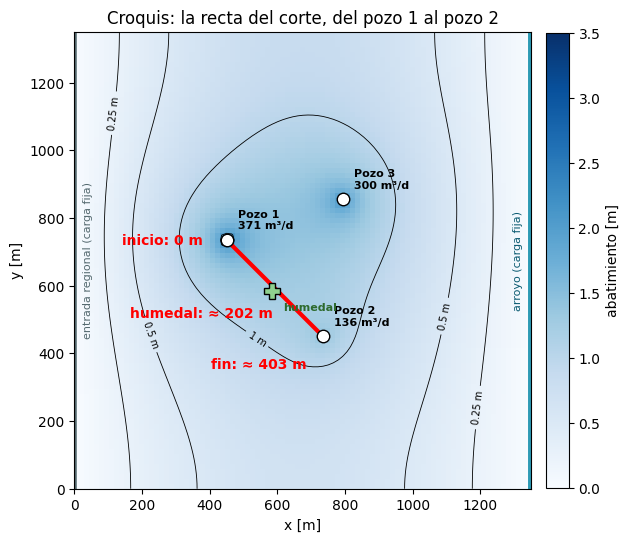

In [32]:
# Croquis: el mapa del óptimo con humedal y, en rojo, la recta del corte (del pozo 1 al pozo 2).
x1, y1 = hidra.pozos_xy()[0]                     # dónde está el pozo 1 [m]
x2, y2 = hidra.pozos_xy()[1]                     # dónde está el pozo 2 [m]
xh, yh = hidra.humedal_xy()                      # dónde está el humedal [m]

ax = hidra.mapa(r_h, titulo="Croquis: la recta del corte, del pozo 1 al pozo 2")
ax.plot([x1, x2], [y1, y2], color="red", lw=3)   # la recta del corte
ax.text(x1 - 310, y1 - 15, "inicio: 0 m", color="red", fontsize=10, fontweight="bold")          # rótulos con la distancia al pozo 1
ax.text(xh - 420, yh - 80, "humedal: ≈ 202 m", color="red", fontsize=10, fontweight="bold")
ax.text(x2 - 330, y2 - 95, "fin: ≈ 403 m", color="red", fontsize=10, fontweight="bold")
plt.show()

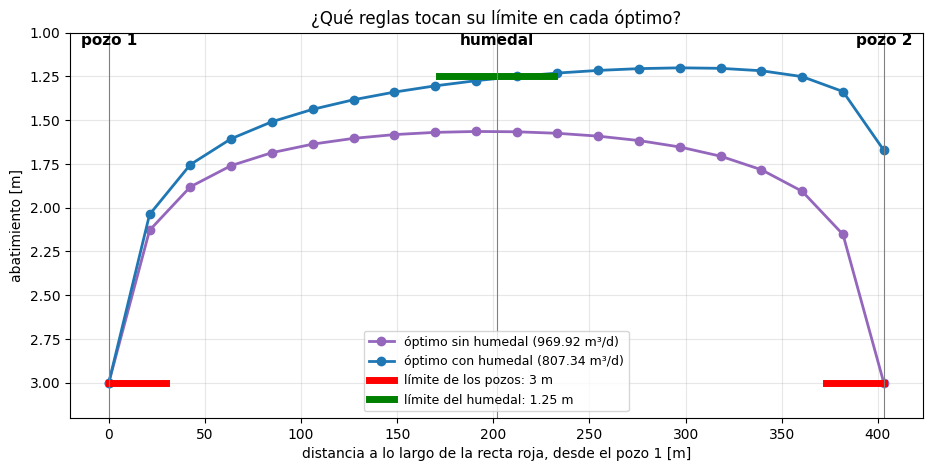

                       pozo 1   humedal   pozo 2
límite                  3.00     1.25      3.00
óptimo sin humedal      3.0     1.55      3.0
óptimo con humedal      3.0     1.25      1.67


In [33]:
# El corte: caminar por la recta roja y medir el abatimiento en 20 puntos, con los dos óptimos.
xs = np.linspace(x1, x2, 20)                     # 20 puntos sobre la recta, del pozo 1 al pozo 2
ys = np.linspace(y1, y2, 20)
d = np.sqrt((xs - x1) ** 2 + (ys - y1) ** 2)     # distancia de cada punto al pozo 1 [m] (eje horizontal)
d_hum = np.sqrt((xh - x1) ** 2 + (yh - y1) ** 2) # a qué distancia del pozo 1 queda el humedal [m]
d_p2 = d[-1]                                     # a qué distancia queda el pozo 2 [m]

s_sin = [r_opt.en(x, y) for x, y in zip(xs, ys)] # abatimiento en cada punto con el óptimo SIN humedal
s_con = [r_h.en(x, y) for x, y in zip(xs, ys)]   # abatimiento en cada punto con el óptimo CON humedal

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(d, s_sin, "o-", lw=2, color="tab:purple", label="óptimo sin humedal (969.92 m³/d)")
ax.plot(d, s_con, "o-", lw=2, color="tab:blue", label="óptimo con humedal (807.34 m³/d)")

# cada límite se dibuja solo donde aplica: 3 m en cada pozo y 1.25 m en el humedal
ax.plot([0, 30], [3.0, 3.0], color="red", lw=5)
ax.plot([d_p2 - 30, d_p2], [3.0, 3.0], color="red", lw=5, label="límite de los pozos: 3 m")
ax.plot([d_hum - 30, d_hum + 30], [1.25, 1.25], color="green", lw=5, label="límite del humedal: 1.25 m")

# dónde está cada cosa
for lugar, nombre in [(0, "pozo 1"), (d_hum, "humedal"), (d_p2, "pozo 2")]:
    ax.axvline(lugar, color="gray", lw=0.8)
    ax.text(lugar, 1.07, nombre, ha="center", fontsize=11, fontweight="bold")

ax.set_ylim(3.2, 1.0)                            # el eje al revés: hacia abajo = baja más el nivel, como en un pozo
ax.set_xlabel("distancia a lo largo de la recta roja, desde el pozo 1 [m]")
ax.set_ylabel("abatimiento [m]")
ax.set_title("¿Qué reglas tocan su límite en cada óptimo?")
ax.legend(loc="lower center", fontsize=9)
ax.grid(alpha=0.3)
plt.show()

# Los valores exactos en los tres lugares (de la corrida completa, no del corte)
print("                       pozo 1   humedal   pozo 2")
print("límite                  3.00     1.25      3.00")
print("óptimo sin humedal     ", round(r_opt.abatimiento_pozos[0], 2), "   ", round(r_opt.abatimiento_humedal, 2), "    ", round(r_opt.abatimiento_pozos[1], 2))
print("óptimo con humedal     ", round(r_h.abatimiento_pozos[0], 2), "   ", round(r_h.abatimiento_humedal, 2), "    ", round(r_h.abatimiento_pozos[1], 2))

**Cómo leer el corte.** El eje vertical está invertido: más abajo, más baja el nivel. Cada curva tiene dos «pozos» hacia abajo en los
extremos (los conos de los pozos 1 y 2) y una «loma» en medio, donde está el humedal.

| | Pozo 1 (límite 3 m) | Humedal (límite 1.25 m) | Pozo 2 (límite 3 m) |
|---|---|---|---|
| **Sin humedal** (969.92 m³/d) | 3.00 m: **en el límite** | 1.55 m: **se pasa** | 3.00 m: **en el límite** |
| **Con humedal** (807.34 m³/d) | 3.00 m: **en el límite** | 1.25 m: **en el límite** | 1.67 m: le sobran 1.33 m |

- **Sin humedal**, las reglas activas son las de los **dos pozos**: los dos tocan sus 3 m. Pero el humedal baja 1.55 m, más que sus
  1.25 m, y por eso esa decisión ya no sirve cuando se protege el humedal.
- **Con humedal**, las reglas activas son el **pozo 1** y el **humedal**. Para cumplir con el humedal, el pozo 2 (el que más lo
  afecta) baja su bombeo de 329 a 136 m³/d y le sobra margen; el pozo 1 aprovecha y sube de 341 a 371 m³/d.

**La idea.** El óptimo «empuja» el bombeo hasta que algunas reglas quedan justo en su límite. Con dos decisiones, son dos reglas: las
dos rectas que se cruzan en el vértice. Las demás reglas quedan con holgura y no deciden nada.

### 8.3 ¿Cuánto cuesta cada centímetro del humedal?

**La pregunta.** El límite de 1.25 m del humedal no es una ley de la naturaleza: lo pone el regulador. Fritz podría ir a negociarlo
y preguntar: *si me dejan bajar el humedal un centímetro más, ¿cuánta agua más puedo bombear?* Y al revés: si el regulador lo
aprieta, ¿cuánta agua pierde y qué pozo lo paga?

**La idea.** Cambiar el límite del humedal solo cambia **un número**: el último valor de b. En el plano $(p_1, p_2)$ eso **mueve la
recta del humedal** paralela a sí misma: más arriba si se afloja, más abajo si se aprieta. Al moverse la recta, se mueve el vértice
óptimo. Primero el croquis con tres límites:

humedal con 1.00 m → óptimo p1 = 371.2, p2 = 0.0, Z = 671.2 m³/d
humedal con 1.56 m → óptimo p1 = 341.2, p2 = 328.8, Z = 969.9 m³/d


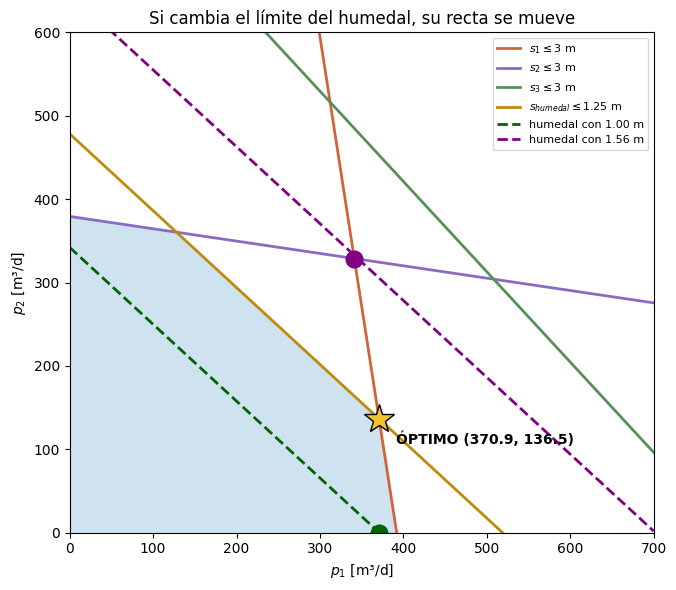

In [34]:
# Croquis: la región de hoy (humedal con 1.25 m) y dónde quedaría la recta del humedal con otros dos límites.
ax = hidra.graficar_region_factible(A_total, b_total, nombres, p_optimo=(p1_h, p2_h),
                                    titulo="Si cambia el límite del humedal, su recta se mueve")
p1_eje = np.linspace(0, 700, 50)                         # valores de p1 para dibujar las rectas
for lim, color in [(1.00, "darkgreen"), (1.56, "purple")]:
    b_hum = lim - alpha_humedal[2] * p3                  # el nuevo lado derecho de la regla del humedal
    p2_recta = (b_hum - alpha_humedal[0] * p1_eje) / alpha_humedal[1]   # la recta: despejar p2 de la regla
    ax.plot(p1_eje, p2_recta, "--", lw=2, color=color, label=f"humedal con {lim:.2f} m")
    b_lim = b_total.copy()                               # las reglas de hoy...
    b_lim[3] = b_hum                                     # ...con ese límite del humedal
    sol_lim = linprog(c, A_ub=A_total, b_ub=b_lim, bounds=cotas)
    ax.plot(sol_lim.x[0], sol_lim.x[1], "o", ms=12, color=color)    # su óptimo
    print(f"humedal con {lim:.2f} m → óptimo p1 = {sol_lim.x[0]:.1f}, p2 = {sol_lim.x[1]:.1f}, Z = {sol_lim.x.sum() + p3:.1f} m³/d")
ax.set_xlim(0, 700)
ax.set_ylim(0, 600)
ax.legend(loc="upper right", fontsize=8)
plt.show()

In [35]:
# Ahora con todos los límites, de 0.70 a 2.00 m, cada centímetro: 131 problemas de linprog, uno tras otro.

def optimo_con_humedal(limite):
    # Resuelve el problema de hoy cambiando solo el límite del humedal; devuelve p1, p2 y Z del óptimo.
    b_lim = b_total.copy()                           # las reglas de hoy...
    b_lim[3] = limite - alpha_humedal[2] * p3        # ...con otro límite en la cuarta regla (el humedal)
    sol_lim = linprog(c, A_ub=A_total, b_ub=b_lim, bounds=cotas)
    p1, p2 = sol_lim.x
    return p1, p2, p1 + p2 + p3

limites = np.arange(0.70, 2.01, 0.01)                # 0.70, 0.71, 0.72, ..., 2.00
Z_lim, p1_lim, p2_lim = [], [], []                   # aquí se guarda el resultado de cada límite
for lim in limites:
    p1_, p2_, Z_ = optimo_con_humedal(lim)
    Z_lim.append(Z_)
    p1_lim.append(p1_)
    p2_lim.append(p2_)

# El precio de un centímetro: cuánto más se bombea con 1.26 m que con 1.25 m
precio = optimo_con_humedal(1.26)[2] - optimo_con_humedal(1.25)[2]
print("cada cm de humedal vale", round(precio, 1), "m³/d (cerca de 1.25 m)")

# Algunos límites, para ver dónde cambia el comportamiento (las gráficas de abajo muestran todos)
print("\nlímite      p1       p2        Z")
for lim in [1.00, 1.03, 1.04, 1.25, 1.55, 1.56, 2.00]:
    p1_, p2_, Z_ = optimo_con_humedal(lim)
    print(f"{lim:.2f} m  {p1_:7.2f}  {p2_:7.2f}  {Z_:7.2f}")

cada cm de humedal vale 5.4 m³/d (cerca de 1.25 m)

límite      p1       p2        Z
1.00 m   371.19     0.00   671.19
1.03 m   388.92     0.00   688.92
1.04 m   391.50     3.06   694.57
1.25 m   370.88   136.46   807.34
1.55 m   341.42   327.02   968.44
1.56 m   341.15   328.77   969.92
2.00 m   341.15   328.77   969.92


La tabla ya deja ver los dos cambios: entre 1.03 y 1.04 m **el pozo 2 se enciende** (pasa de 0 a 3.06 m³/d), y entre 1.55 y
1.56 m el total **llega a 969.92 m³/d y ya no sube**, el mismo óptimo que sin humedal.

Los 131 resultados se ven mejor en dos gráficas. En las dos, el eje horizontal es **el límite que el regulador le pone al
humedal**: a la izquierda, un límite estricto (el humedal casi no puede bajar); a la derecha, uno flojo. La estrella o la línea
punteada marcan **hoy, 1.25 m**. Las tres franjas de color son tres zonas en las que el óptimo se comporta distinto.

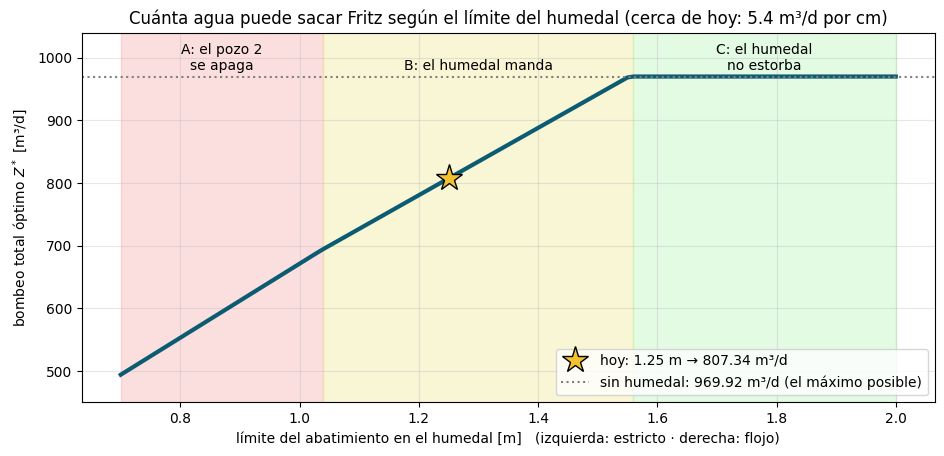

In [36]:
# Gráfica 1: el bombeo total óptimo Z* según el límite del humedal.
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.axvspan(0.70, 1.04, color="lightcoral", alpha=0.25)          # zona A: humedal muy estricto
ax.axvspan(1.04, 1.56, color="khaki", alpha=0.35)               # zona B: el humedal manda
ax.axvspan(1.56, 2.00, color="lightgreen", alpha=0.25)          # zona C: el humedal ya no estorba
ax.text(0.87, 980, "A: el pozo 2\nse apaga", ha="center", fontsize=10)
ax.text(1.30, 980, "B: el humedal manda", ha="center", fontsize=10)
ax.text(1.78, 980, "C: el humedal\nno estorba", ha="center", fontsize=10)

ax.plot(limites, Z_lim, lw=3, color="#0B5B72")                  # la curva: un punto por cada límite probado
ax.plot(1.25, Z_h, "*", ms=20, mfc="#f2c230", mec="k", label=f"hoy: 1.25 m → {Z_h:.2f} m³/d")
ax.axhline(Z_opt, color="gray", ls=":", label=f"sin humedal: {Z_opt:.2f} m³/d (el máximo posible)")
ax.set_ylim(450, 1040)
ax.set_xlabel("límite del abatimiento en el humedal [m]   (izquierda: estricto · derecha: flojo)")
ax.set_ylabel("bombeo total óptimo $Z^*$ [m³/d]")
ax.set_title(f"Cuánta agua puede sacar Fritz según el límite del humedal (cerca de hoy: {precio:.1f} m³/d por cm)")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
plt.show()

**Cómo leer la gráfica 1.** Cada punto de la curva es un problema de programación lineal resuelto: «si el límite del humedal fuera
este, lo más que Fritz puede bombear es esto». Leámosla de derecha a izquierda, como si el regulador fuera apretando:

- **Zona C (1.56 m o más): la curva es plana en 969.92 m³/d.** Aflojar más no da ni un litro (abajo se explica por qué).
- **Zona B (de 1.04 a 1.56 m): la curva es una recta que sube.** Aquí el humedal es una regla **activa**: cada centímetro que se
  aprieta le quita a Fritz unos **5.4 m³/d** (es la pendiente). Hoy, con 1.25 m, está en 807.34 m³/d: 162.6 menos que sin humedal.
- **Zona A (menos de 1.04 m): la recta se vuelve más empinada.** Cada centímetro cuesta ahora unos 5.9 m³/d. Con 0.70 m, Fritz solo
  podría sacar 493.91 m³/d, la mitad que sin humedal. El porqué está en la gráfica 2.

**¿Por qué ya no sube después de 1.56 m?** Porque desde ahí **el humedal ya no es lo que frena a Fritz: lo frenan los dos pozos.**

1. Sin humedal, el mejor bombeo es $p = (341.15,\ 328.77)$, con los pozos 1 y 2 justo en sus 3 m. Con ese bombeo, el humedal baja
   **1.553 m**.
2. Si el límite del humedal es **menor** que 1.553 m (por ejemplo, 1.25), ese bombeo no se permite y hay que bombear menos: cada
   centímetro que se afloja da más agua (zona B).
3. Si el límite es **1.553 m o más**, ese bombeo **ya cumple** la regla del humedal, y el óptimo vuelve a ser el de los dos pozos.
4. Para bombear más de 969.92 habría que subir $p_1$ o $p_2$, y entonces el pozo 1 o el pozo 2 pasaría de sus 3 m. Esas reglas no
   cambian al aflojar el humedal. **Aflojar una regla que ya se cumple con holgura no sirve de nada.**

Piénsalo como una puerta con dos cerrojos: en la zona B la detiene el cerrojo del humedal, y al aflojarlo se abre un poco más; desde
1.553 m ese cerrojo ya está abierto, pero la puerta no se mueve porque la sujeta el otro, el de los pozos. En la tabla se ve: con
1.55 m, Z = 968.44 (el humedal todavía frena un poco); con 1.56 m y con 2.00 m, Z = 969.92. Y en el croquis, la recta morada del
humedal con 1.56 m pasa justo por el vértice de los dos pozos: si se afloja más, la recta se aleja, pero el vértice ya no se mueve.

**¿Qué es un quiebre?** Es un punto donde la curva **cambia de pendiente**. En la gráfica 1 hay dos, en 1.04 m y en 1.56 m. Para
entenderlos hay que recordar dos cosas: el óptimo siempre está en una **esquina** de la región, y cada esquina es el cruce de **dos
reglas activas**.

- **Entre 1.04 y 1.56 m (zona B)**, la esquina óptima es siempre el cruce de las mismas dos rectas: **pozo 1** y **humedal**. El óptimo
  se calcula resolviendo esas dos reglas como igualdades (dos ecuaciones con dos incógnitas). Al cambiar el límite del humedal solo
  cambia un número de una ecuación, y la solución cambia en proporción. Por eso la curva es una **recta**: cada centímetro vale lo
  mismo, 5.4 m³/d.
- **En 1.56 m**, al aflojar el humedal, la esquina llega hasta la recta del pozo 2. Desde ahí la esquina óptima es el cruce de
  **pozo 1** y **pozo 2**, que no dependen del humedal: la pendiente se vuelve **cero** (zona C).
- **En 1.04 m**, al apretar el humedal, la esquina baja hasta tocar el eje $p_2 = 0$: el pozo 2 ya no puede bombear menos. Desde ahí la
  esquina es el cruce del **humedal** con el **eje** $p_2 = 0$, y el pozo 1 deja de estar en sus 3 m. Cambian las reglas activas, y
  con ellas la pendiente (zona A).

**En resumen:** cada tramo recto corresponde a una pareja de reglas activas; un quiebre es el momento en que una regla entra y otra sale.

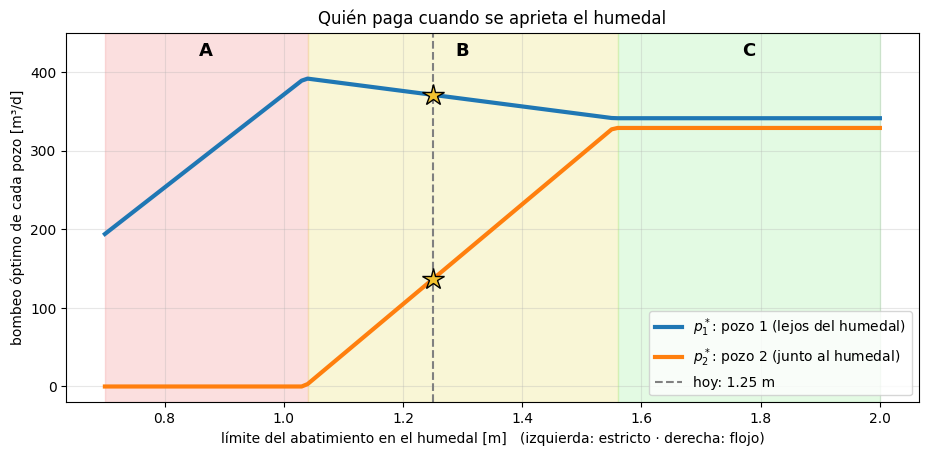

In [37]:
# Gráfica 2: cuánto bombea cada pozo en el óptimo, según el límite del humedal.
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.axvspan(0.70, 1.04, color="lightcoral", alpha=0.25)          # las mismas tres zonas
ax.axvspan(1.04, 1.56, color="khaki", alpha=0.35)
ax.axvspan(1.56, 2.00, color="lightgreen", alpha=0.25)
ax.text(0.87, 420, "A", ha="center", fontsize=13, fontweight="bold")
ax.text(1.30, 420, "B", ha="center", fontsize=13, fontweight="bold")
ax.text(1.78, 420, "C", ha="center", fontsize=13, fontweight="bold")

ax.plot(limites, p1_lim, lw=3, label="$p_1^*$: pozo 1 (lejos del humedal)")
ax.plot(limites, p2_lim, lw=3, label="$p_2^*$: pozo 2 (junto al humedal)")
ax.axvline(1.25, color="gray", ls="--", label="hoy: 1.25 m")
ax.plot([1.25, 1.25], [p1_h, p2_h], "*", ms=16, mfc="#f2c230", mec="k")   # el óptimo de hoy: 370.88 y 136.46
ax.set_xlabel("límite del abatimiento en el humedal [m]   (izquierda: estricto · derecha: flojo)")
ax.set_ylabel("bombeo óptimo de cada pozo [m³/d]")
ax.set_ylim(-20, 450)
ax.set_title("Quién paga cuando se aprieta el humedal")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
plt.show()

**Cómo leer la gráfica 2.** Ya no es el total, sino **cómo se reparte** entre los dos pozos que se deciden. Otra vez de derecha a
izquierda:

- **Zona C:** los dos pozos bombean lo del óptimo sin humedal, 341.15 y 328.77 m³/d, y los dos están en sus 3 m.
- **Zona B:** al apretar el humedal, **el pozo 2 baja rápido** (de 329 a casi 0 m³/d) y **el pozo 1 sube un poco** (de 341 a 391).
  El pozo 2 está junto al humedal: cada m³/d que bombea lo baja 0.001836 m, más que el pozo 1 (0.001692). Así que el óptimo le quita
  agua al pozo 2 y le da una parte al pozo 1, que sigue tocando sus 3 m. Hoy: 370.88 y 136.46 m³/d.
- **Zona A:** el pozo 2 ya está en **cero** y no puede bajar más (no se inyecta agua). Para seguir cuidando el humedal, ahora tiene
  que bajar **el pozo 1**, que deja de tocar sus 3 m. Por eso en la gráfica 1 cada centímetro cuesta más: ya no hay a quién quitarle
  agua barata. Es el caso degenerado de la sección 9: el óptimo cae sobre el eje $p_2 = 0$.

**En una frase para Fritz:** hoy cada centímetro de humedal le cuesta unos 5.4 m³/d, lo paga casi todo el pozo 2, y si el regulador
bajara el límite de 1.04 m, el pozo 2 se apagaría por completo.

A esos 5.4 m³/d por centímetro, lo que se gana por aflojar una restricción una unidad, se le llama **precio sombra**. `linprog` lo da
gratis (`sol_h.ineqlin.marginals`): es otra ventaja del método clásico que las metaheurísticas no tienen.

### 8.4 Tu mejor marca contra el óptimo

¿Te acuerdas de tu mejor marca de la sección 5, a prueba y error, con el humedal? Compárala con el óptimo con garantía.

In [38]:
# Tu mejor marca de la sección 5 contra el óptimo con garantía.
MI_MEJOR_MARCA = 750      # ✏️ escribe el total (m³/d) de tu mejor marca de la sección 5
print(f"Tu mejor marca: {MI_MEJOR_MARCA:.0f} m³/d | el óptimo con garantía: {Z_h:.2f} m³/d | "
      f"te faltaban {Z_h - MI_MEJOR_MARCA:.1f} m³/d ({100 * (Z_h - MI_MEJOR_MARCA) / Z_h:.1f} %)")

Tu mejor marca: 750 m³/d | el óptimo con garantía: 807.34 m³/d | te faltaban 57.3 m³/d (7.1 %)


<div style="border-left: 5px solid #C08A0B; padding: 6px 12px; background: rgba(127,127,127,0.08);">✔ <b>Punto de control.</b> <b>Z* = 807.34 m³/d</b> con el humedal: el pozo 2 baja y el pozo 1 sube. → Siguiente: <a href="#s9">9 · Lo que puede salir mal</a></div>

<div style="background:#54696F; color:white; padding:14px 18px; border-radius:6px; margin-top:36px;"><span style="font-size:1.4em; font-weight:bold;">PARTE III · Los límites del método</span><br><span style="opacity:0.9;">secciones 9 a 11 · 🏫 si da tiempo, si no 🏠 en casa · 17 min</span></div>

<hr style="border: none; border-top: 4px solid #54696F; margin: 28px 0 4px 0;">
<p style="color:#54696F; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 9 · LO QUE PUEDE SALIR MAL</p>

<a id="s9"></a>

## 9 · Lo que puede salir mal (7 min)

<span style="color:#54696F">**⏱ 7 min · 🏫 si da tiempo; si no, 🏠 en casa · Al terminar reconocerás un problema no acotado, uno infactible y uno degenerado.**</span>

`linprog` no siempre encuentra un óptimo. Hay tres situaciones que hay que saber reconocer y **leer en términos hidrogeológicos**. Las provocamos a propósito
con el problema de Fritz. `linprog` lo avisa con `status` (0 = encontró el óptimo, 2 = infactible, 3 = no acotado) y un mensaje.

In [39]:
# resolver(...): llama a linprog y reporta qué pasó, con el status en palabras.
def resolver(A, b, cotas, nombre):
    # resuelve el problema de Fritz con las reglas (A, b) y las cotas de cada bomba, y reporta qué pasó
    r = linprog(c=[-1, -1], A_ub=A, b_ub=b, bounds=cotas, method="highs")
    texto = f"{nombre:42s} status {r.status}: {r.message.split('(')[0].strip()}"   # status 0 = óptimo, 2 = infactible, 3 = no acotado
    if r.status == 0:
        texto += f"  →  p1 = {r.x[0]:.2f}, p2 = {r.x[1]:.2f}, Z = {r.x.sum() + p3:.2f} m³/d"   # solo si hay óptimo se reportan los bombeos
    print(texto)
    return r

resolver(A_total, b_total, [(0, hidra.P_MAX)] * 2, "el problema de hoy")   # [(0, 1000)] * 2: la misma cota para p1 y p2

el problema de hoy                         status 0: Optimization terminated successfully.  →  p1 = 370.88, p2 = 136.46, Z = 807.34 m³/d


        message: Optimization terminated successfully. (HiGHS Status 7: Optimal)
        success: True
         status: 0
            fun: -507.34040295578075
              x: [ 3.709e+02  1.365e+02]
            nit: 3
          lower:  residual: [ 3.709e+02  1.365e+02]
                 marginals: [ 0.000e+00  0.000e+00]
          upper:  residual: [ 6.291e+02  8.635e+02]
                 marginals: [ 0.000e+00  0.000e+00]
          eqlin:  residual: []
                 marginals: []
        ineqlin:  residual: [ 0.000e+00  1.329e+00  3.351e-01  0.000e+00]
                 marginals: [-1.347e+01 -0.000e+00 -0.000e+00 -5.370e+02]
 mip_node_count: 0
 mip_dual_bound: 0.0
        mip_gap: 0.0

### 9.1 No acotado: el objetivo crece sin límite

Ocurre cuando **falta una restricción**. ¿Y si olvidamos la capacidad de las bombas (1 000 m³/d)? ¿Y si además olvidamos las reglas de abatimiento?

In [40]:
# No acotado: quitar límites. Sin capacidad de bombas el acuífero todavía limita; sin reglas de abatimiento, nada limita.
resolver(A_total, b_total, [(0, None)] * 2, "sin la capacidad de las bombas")          # None = sin tope
resolver(None, None, [(0, None)] * 2, "sin las reglas de abatimiento ni la capacidad")  # sin A ni b: solo p ≥ 0

sin la capacidad de las bombas             status 0: Optimization terminated successfully.  →  p1 = 370.88, p2 = 136.46, Z = 807.34 m³/d
sin las reglas de abatimiento ni la capacidad status 3: The problem is unbounded.


       message: The problem is unbounded. (HiGHS Status 10: model_status is Unbounded; primal_status is Feasible)
       success: False
        status: 3
           fun: None
             x: None
           nit: 0
         lower:  residual: None
                marginals: None
         upper:  residual: None
                marginals: None
         eqlin:  residual: None
                marginals: None
       ineqlin:  residual: None
                marginals: None

Sin la capacidad de las bombas **no pasa nada**: el acuífero mismo limita el bombeo (los 3 m y el humedal llegan antes que los 1 000 m³/d). Pero sin las
reglas de abatimiento no hay nada que detenga a $Z$: **no acotado**. En la práctica significa que el modelo olvidó algo físico.

### 9.2 Infactible: las reglas se contradicen

Ocurre cuando **ninguna decisión** cumple todas las reglas a la vez. Por ejemplo, si el contrato del pozo 3 sube a 500 m³/d:

In [41]:
# Infactible: con un contrato de 500 m³/d en el pozo 3, ninguna decisión cumple todas las reglas.
p3_contrato = 500
b_contrato = np.concatenate([hidra.S_MAX - alpha[:, 2] * p3_contrato, [hidra.S_MAX_HUMEDAL - alpha_humedal[2] * p3_contrato]])   # b con el pozo 3 en 500
resolver(A_total, b_contrato, [(0, hidra.P_MAX)] * 2, "contrato del pozo 3 en 500 m³/d")
print(f"el pozo 3, solo y con 500 m³/d, abate su propio pozo {alpha[2, 2] * p3_contrato:.2f} m: ya rompe la regla de 3 m aunque p1 = p2 = 0")

contrato del pozo 3 en 500 m³/d            status 2: The problem is infeasible.
el pozo 3, solo y con 500 m³/d, abate su propio pozo 3.49 m: ya rompe la regla de 3 m aunque p1 = p2 = 0


Aunque los pozos 1 y 2 se apaguen, el pozo 3 ya rompe su propia regla: **no existe región factible**. La lectura para Fritz: *«ese contrato no se puede
cumplir sin violar la norma; hay que renegociarlo»*.

### 9.3 Degenerado: una variable vale cero

No es un error: el óptimo existe, pero queda en un **eje**. Si la autoridad baja el límite del humedal a 1.0 m:

In [42]:
# Degenerado: con el humedal a 1.0 m, el óptimo cae sobre un eje (un pozo se apaga).
b_estricto = b_total.copy()                           # una copia, para no cambiar b_total
b_estricto[-1] = 1.0 - alpha_humedal[2] * p3          # la regla del humedal, ahora con 1.0 m
resolver(A_total, b_estricto, [(0, hidra.P_MAX)] * 2, "humedal a 1.0 m")

humedal a 1.0 m                            status 0: Optimization terminated successfully.  →  p1 = 371.19, p2 = 0.00, Z = 671.19 m³/d


        message: Optimization terminated successfully. (HiGHS Status 7: Optimal)
        success: True
         status: 0
            fun: -371.1915139964696
              x: [ 3.712e+02  0.000e+00]
            nit: 1
          lower:  residual: [ 3.712e+02  0.000e+00]
                 marginals: [ 0.000e+00  8.488e-02]
          upper:  residual: [ 6.288e+02  1.000e+03]
                 marginals: [ 0.000e+00  0.000e+00]
          eqlin:  residual: []
                 marginals: []
        ineqlin:  residual: [ 1.408e-01  2.293e+00  4.793e-01  0.000e+00]
                 marginals: [-0.000e+00 -0.000e+00 -0.000e+00 -5.909e+02]
 mip_node_count: 0
 mip_dual_bound: 0.0
        mip_gap: 0.0

El óptimo **apaga el pozo 2**: es el que más abate al humedal por cada m³/d. Matemáticamente es un vértice sobre el eje $p_2 = 0$; hidrogeológicamente,
*«con esa norma, el pozo 2 no conviene»*.

### 9.4 Los tres casos, dibujados

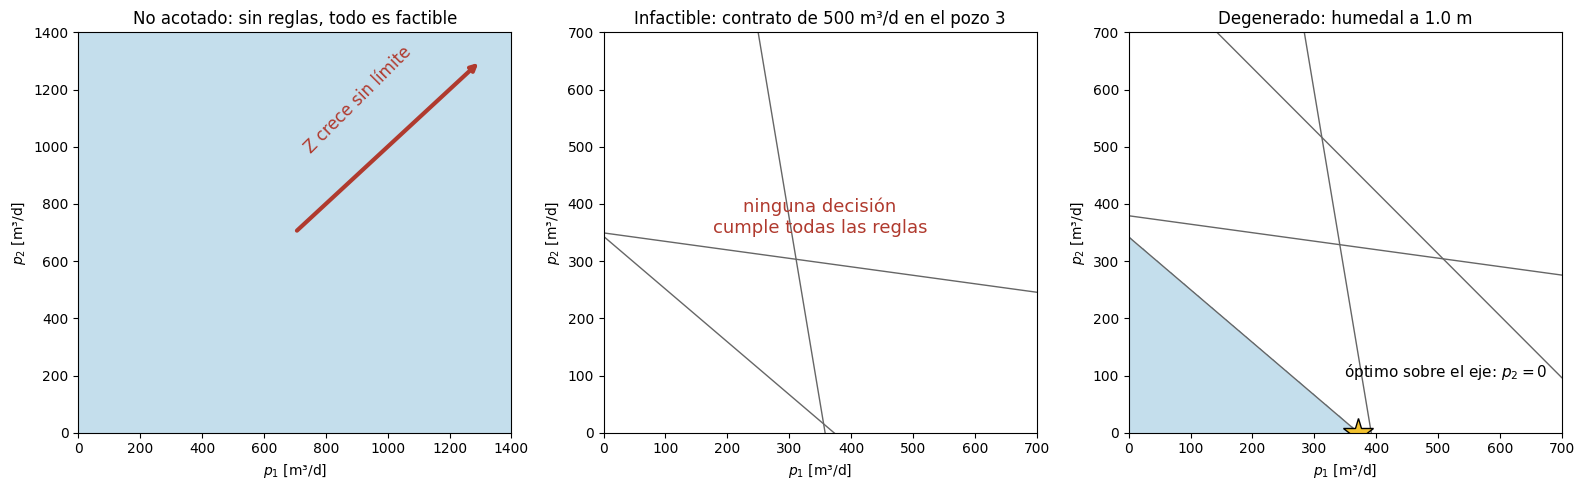

In [43]:
# Los tres casos, dibujados. region(...) pinta las decisiones que cumplen todas las reglas.
def region(ax, A, b, titulo, xmax=1400):
    g = np.linspace(0, xmax, 400); G1, G2 = np.meshgrid(g, g)   # una malla fina de decisiones (p1, p2)
    ok = np.ones_like(G1, bool)                                  # al principio, todas cumplen
    if A is not None:
        for (a1, a2), bk in zip(A, b):                           # una regla a la vez: a1·p1 + a2·p2 ≤ bk
            ok &= a1 * G1 + a2 * G2 <= bk                        # se quedan solo las que también cumplen esta
            ax.plot(g, (bk - a1 * g) / a2, color="0.4", lw=1)    # la recta de la regla (despejando p2)
    if ok.any():
        ax.contourf(G1, G2, ok, levels=[0.5, 1.5], colors=["#9ec9e0"], alpha=0.6)   # pinta de azul la región que cumple todo
    ax.set_xlim(0, xmax); ax.set_ylim(0, xmax); ax.set_xlabel("$p_1$ [m³/d]"); ax.set_ylabel("$p_2$ [m³/d]"); ax.set_title(titulo)

fig, ejes = plt.subplots(1, 3, figsize=(16, 5))
region(ejes[0], None, None, "No acotado: sin reglas, todo es factible")
ejes[0].annotate("", xy=(1300, 1300), xytext=(700, 700), arrowprops=dict(arrowstyle="-|>", lw=3, color="#B03A2E"))   # flecha: Z crece hacia allá
ejes[0].text(720, 980, "Z crece sin límite", color="#B03A2E", fontsize=12, rotation=45)
region(ejes[1], A_total, b_contrato, "Infactible: contrato de 500 m³/d en el pozo 3", xmax=700)
ejes[1].text(350, 350, "ninguna decisión\ncumple todas las reglas", ha="center", fontsize=13, color="#B03A2E")
r_deg = linprog(c=[-1, -1], A_ub=A_total, b_ub=b_estricto, bounds=[(0, hidra.P_MAX)] * 2, method="highs")   # el caso degenerado, para marcar su óptimo
region(ejes[2], A_total, b_estricto, "Degenerado: humedal a 1.0 m", xmax=700)
ejes[2].plot(*r_deg.x, "*", ms=22, mfc="#f2c230", mec="k"); ejes[2].annotate("óptimo sobre el eje: $p_2 = 0$", r_deg.x, xytext=(-10, 40),
                                                                             textcoords="offset points", fontsize=11)
plt.tight_layout(); plt.show()

<div style="border-left: 5px solid #54696F; padding: 6px 12px; background: rgba(127,127,127,0.08);">✔ <b>Punto de control.</b> <code>linprog</code> respondió con status 3 (no acotado), 2 (infactible) y 0 con una variable en cero (degenerado). → Siguiente: <a href="#s10">10 · ¿Cuándo basta el método clásico?</a></div>

<hr style="border: none; border-top: 4px solid #54696F; margin: 28px 0 4px 0;">
<p style="color:#54696F; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 10 · ¿CUÁNDO BASTA EL MÉTODO CLÁSICO?</p>

<a id="s10"></a>

## 10 · ¿Cuándo basta el método clásico? (8 min)

<span style="color:#54696F">**⏱ 8 min · 🏫 si da tiempo; si no, 🏠 en casa · Al terminar sabrás cuándo `linprog` ya no sirve y qué hace una metaheurística.**</span>

### 10.1 El problema de Fritz en los cuatro ejes

| Eje | El problema de hoy | Si cambiara a… | …ya no bastaría `linprog` porque |
|---|---|---|---|
| Objetivo y restricciones | **lineales** (superposición) | el costo de la energía, que crece con el abatimiento | el objetivo deja de ser $c^\top x$ |
| Variables | **continuas** (m³/d) | decidir qué pozos perforar u operar | las variables son sí o no |
| Número de objetivos | **uno** (el agua) | agua, costo y humedal a la vez | no hay un solo óptimo, sino un frente (sesión 3) |
| Conocimiento | **determinista** (una geología) | muchas geologías posibles | hay que decidir con incertidumbre (sesión 4) |

Hoy el problema cayó en las cuatro columnas fáciles: por eso `linprog` bastó, en milisegundos y **con garantía**.

### 10.2 Fritz paga la luz: un objetivo no lineal

Fritz vende el agua de los pozos 1 y 2 a $P = 0.11$ \$/m³, pero paga la energía de subirla. La altura de bombeo es la profundidad al nivel estático más el
abatimiento, así que el costo **crece con el abatimiento**:

$$
\max\; B(p_1, p_2) = \sum_{i=1}^{2} \Big[ P\,p_i \;-\; c_i\,p_i\,\big(\text{H}_i - h_i^0 + s_i(\mathbf{p})\big) \Big]
$$

con $c = 0.01, 0.015$ \$ por m³ y metro, cota del terreno $\text{H} = 40$ m, nivel estático $h^0 = 34$ m, y las mismas reglas de hoy.

**¿Dónde está lo no lineal?** En el último término. El abatimiento $s_i$ **también depende de los bombeos**: con la matriz de respuesta,
$s_1 = \alpha_{11}\,p_1 + \alpha_{12}\,p_2 + \alpha_{13}\,p_3$. Y en el costo de la energía ese abatimiento se **multiplica** por el
bombeo $p_1$. Al multiplicar aparecen bombeos multiplicados por bombeos:

$$
c_1\,p_1\,s_1 \;=\; c_1\,p_1\,\big(\alpha_{11}\,p_1 + \alpha_{12}\,p_2 + \alpha_{13}\cdot 300\big)
\;=\; \underbrace{c_1\,\alpha_{11}\,p_1^{2}}_{\text{bombeo al cuadrado}} \;+\; \underbrace{c_1\,\alpha_{12}\,p_1\,p_2}_{\text{bombeo por bombeo}} \;+\; \underbrace{c_1\,\alpha_{13}\cdot 300\;p_1}_{\text{lineal}}
$$

Físicamente: bombear más cuesta **doble**: se sube más agua *y* cada metro cúbico se sube desde más hondo, porque el propio bombeo
baja el nivel. Haciendo las cuentas con los números de Fritz (el pozo 2 igual), el beneficio queda:

$$
B(p_1, p_2) \;=\; \underbrace{0.0466\,p_1 \;+\; 0.0152\,p_2}_{\text{parte lineal}}
\;\underbrace{-\;0.0000678\,p_1^{2} \;-\; 0.000106\,p_2^{2} \;-\; 0.0000262\,p_1\,p_2}_{\text{parte no lineal: cuadrados y productos}}
$$

La parte lineal sola diría «bombea todo lo que puedas» (como hoy); la parte no lineal castiga bombear mucho, y cada vez más. Por eso el
óptimo ya **no está en una esquina**. Y `linprog`, que solo acepta objetivos lineales ($c^\top x$, sin cuadrados ni productos), no
lo puede resolver.

La celda siguiente programa $B$ y hace la primera prueba: **¿el óptimo de la sección 8, el que más agua saca, sigue siendo el
mejor ahora que Fritz paga la luz?**

In [44]:
# Fritz paga la luz: el objetivo ya no es el bombeo total sino el beneficio en pesos, que no es lineal.
PRECIO = 0.11                                     # $ por m³
C_E = np.array([0.01, 0.015])                     # costo de la energía de los pozos 1 y 2 [$ por m³ y por metro de altura]
ALTURA = 40.0 - 34.0                              # cota del terreno menos nivel estático [m]

def beneficio(p1, p2):
    s = alpha @ np.array([p1, p2, p3])            # el abatimiento en los 3 pozos, con la matriz
    ingreso = PRECIO * (p1 + p2)                  # lo que Fritz cobra por el agua de los pozos 1 y 2
    energia_1 = C_E[0] * p1 * (ALTURA + s[0])     # luz del pozo 1: costo × agua × altura a vencer (crece con el abatimiento)
    energia_2 = C_E[1] * p2 * (ALTURA + s[1])     # luz del pozo 2
    return ingreso - energia_1 - energia_2        # lo que le queda [$ por día]

def factible(p1, p2):
    s = alpha @ np.array([p1, p2, p3])            # abatimiento en los pozos
    s_hum = alpha_humedal @ np.array([p1, p2, p3])   # abatimiento en el humedal
    return s.max() <= hidra.S_MAX + 1e-9 and s_hum <= hidra.S_MAX_HUMEDAL + 1e-9   # ¿pozos ≤ 3 m y humedal ≤ 1.25 m?

# Primera prueba: el óptimo de bombeo de la sección 8 contra dos decisiones que bombean menos
pruebas = [("óptimo de bombeo (sección 8)", 370.88, 136.46),
           ("otra decisión", 300, 50),
           ("otra decisión", 100, 100)]
for nombre, p1_, p2_ in pruebas:
    total = p1_ + p2_ + p3
    print(f"{nombre:29s} p = ({p1_}, {p2_}) | agua: {total:6.1f} m³/d | beneficio: {beneficio(p1_, p2_):5.2f} $/d | factible: {factible(p1_, p2_)}")

óptimo de bombeo (sección 8)  p = (370.88, 136.46) | agua:  807.3 m³/d | beneficio:  6.73 $/d | factible: True
otra decisión                 p = (300, 50) | agua:  650.0 m³/d | beneficio:  7.97 $/d | factible: True
otra decisión                 p = (100, 100) | agua:  500.0 m³/d | beneficio:  4.18 $/d | factible: True


**Qué muestra el resultado.** Las tres decisiones cumplen todas las reglas, pero:

- el **óptimo de bombeo** de la sección 8 saca **807.34 m³/d** y deja **6.73 \$/d**;
- la decisión $(300,\ 50)$ saca **menos agua (650 m³/d)** y deja **más dinero: 7.97 \$/d**.

Es decir, **el óptimo de la sección 8 ya no es el óptimo**. Al pagar la luz, bombear de más ya no conviene: los últimos metros
cúbicos se suben desde más hondo y cuestan más de lo que se cobran. Cambió la pregunta (de «más agua» a «más dinero») y con ella
cambió la mejor decisión, aunque el acuífero y las reglas sean los mismos. ¿Cuál es la nueva mejor? Eso lo buscaremos en la sección
10.3, sin `linprog`.

**Antes, una comprobación.** Arriba escribimos $B$ desarrollado, con una parte lineal y una no lineal (los cuadrados y el producto
$p_1 p_2$). La celda siguiente saca esos cinco coeficientes de la matriz `alpha`, arma la fórmula y la compara con la función
`beneficio`: si las cuentas de arriba están bien, las dos deben dar lo mismo. De paso, separa cuánto aporta cada parte.

In [45]:
# Comprobar el desarrollo: los coeficientes de la parte lineal y de la no lineal, sacados de alpha, dan el mismo beneficio.
lin_1 = PRECIO - C_E[0] * (ALTURA + alpha[0, 2] * p3)   # coeficiente de p1   (parte lineal)
lin_2 = PRECIO - C_E[1] * (ALTURA + alpha[1, 2] * p3)   # coeficiente de p2   (parte lineal)
cuad_1 = C_E[0] * alpha[0, 0]                           # coeficiente de p1²  (no lineal)
cuad_2 = C_E[1] * alpha[1, 1]                           # coeficiente de p2²  (no lineal)
cruz = C_E[0] * alpha[0, 1] + C_E[1] * alpha[1, 0]      # coeficiente de p1·p2 (no lineal)
print(f"B = {lin_1:.4f} p1 + {lin_2:.4f} p2 - {cuad_1:.7f} p1² - {cuad_2:.6f} p2² - {cruz:.7f} p1·p2")

for p1_, p2_ in [(370.88, 136.46), (336, 34)]:
    parte_lineal = lin_1 * p1_ + lin_2 * p2_
    parte_no_lineal = -(cuad_1 * p1_ ** 2 + cuad_2 * p2_ ** 2 + cruz * p1_ * p2_)
    print(f"p = ({p1_}, {p2_}): lineal {parte_lineal:6.2f} + no lineal {parte_no_lineal:6.2f} = {parte_lineal + parte_no_lineal:5.2f} $/d"
          f"   (beneficio(): {beneficio(p1_, p2_):5.2f})")

B = 0.0466 p1 + 0.0152 p2 - 0.0000678 p1² - 0.000106 p2² - 0.0000262 p1·p2
p = (370.88, 136.46): lineal  19.35 + no lineal -12.62 =  6.73 $/d   (beneficio():  6.73)
p = (336, 34): lineal  16.16 + no lineal  -8.07 =  8.09 $/d   (beneficio():  8.09)


Las dos columnas coinciden: la fórmula desarrollada **es** el beneficio. Y se ve cuánto pesa lo no lineal: en el óptimo de bombeo, la
parte lineal da 19.35 \$/d, pero la no lineal le quita 12.62. Esa resta, que crece con el cuadrado del bombeo, es la que hace que
bombear menos deje más.

El óptimo de bombeo de la sección 8 (370.88, 136.46) **no** es el de mayor beneficio: bombear de más sale caro.

### 10.3 La idea de una metaheurística: proponer y calificar

Sin `linprog`, ¿cómo encontrar el máximo? La idea más simple de todas: **proponer decisiones al azar, calificar cada una y quedarse con la mejor**. No necesita
matriz, ni linealidad, ni fórmula: solo poder **calificar** una decisión. Es la búsqueda al azar, la abuela de las metaheurísticas.

In [46]:
# La metaheurística más simple: probar decisiones al azar y quedarse con la mejor que cumpla las reglas.
def busqueda_al_azar(calificacion, n, semilla=0):
    rng = np.random.default_rng(semilla)                   # generador de números al azar (la semilla hace repetible el resultado)
    mejor_valor, mejor_p, probadas = -np.inf, None, []     # el récord empieza en menos infinito
    for _ in range(n):
        p = rng.uniform(0, hidra.P_MAX, 2)                 # 1.- proponer una decisión al azar
        probadas.append(p)
        if not factible(*p):                               # 2.- ¿respeta las reglas? si no, se descarta
            continue
        valor = calificacion(*p)                           # 3.- calificarla
        if valor > mejor_valor:                            # 4.- quedarse con la mejor
            mejor_valor, mejor_p = valor, p
    return mejor_p, mejor_valor, np.array(probadas)

print("Primero, el problema de hoy (lineal), donde conocemos la verdad: Z* =", round(Z_h, 2), "m³/d")
for n in (100, 1_000, 10_000):                             # cada vez con más decisiones al azar
    p, z, _ = busqueda_al_azar(lambda p1, p2: p1 + p2 + p3, n)   # la calificación es el bombeo total (lambda: una función de una línea)
    print(f"  {n:6d} decisiones al azar → mejor Z = {z:.2f} m³/d (le faltan {Z_h - z:.2f})")

Primero, el problema de hoy (lineal), donde conocemos la verdad: Z* = 807.34 m³/d
     100 decisiones al azar → mejor Z = 798.66 m³/d (le faltan 8.68)
    1000 decisiones al azar → mejor Z = 798.66 m³/d (le faltan 8.68)


   10000 decisiones al azar → mejor Z = 801.70 m³/d (le faltan 5.64)


Se acerca a 807.34, pero **nunca sabe** si ya llegó: no hay certificado. Ahora el problema que `linprog` no puede resolver:

búsqueda al azar (10 000 decisiones): p1 = 336.4, p2 = 33.5 m³/d → beneficio 8.09 $/d


malla fina:                            p1 = 338.0, p2 = 30.0 m³/d → beneficio 8.09 $/d


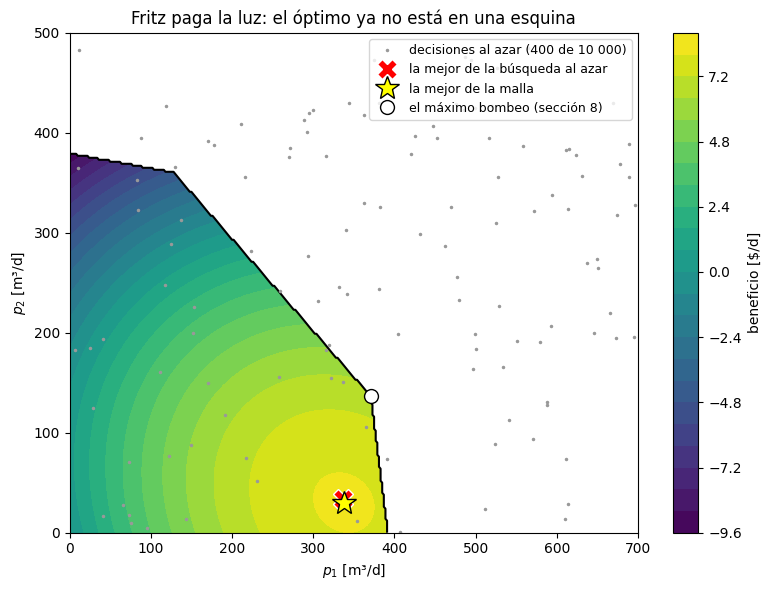

In [47]:
# La búsqueda al azar con el beneficio, comprobada con una malla fina de todas las decisiones posibles.
p_azar, B_azar, probadas = busqueda_al_azar(beneficio, 10_000)
print(f"búsqueda al azar (10 000 decisiones): p1 = {p_azar[0]:.1f}, p2 = {p_azar[1]:.1f} m³/d → beneficio {B_azar:.2f} $/d")

# para comprobarlo, una malla fina (cada 2 m³/d): posible aquí porque son solo dos variables
g = np.arange(0, hidra.P_MAX + 1, 2.0)
G1, G2 = np.meshgrid(g, g)                                  # todas las parejas (p1, p2) de la malla
X = np.stack([G1.ravel(), G2.ravel(), np.full(G1.size, p3)], axis=1)   # una decisión por fila: (p1, p2, 300)
S = X @ alpha.T                                             # el abatimiento de todas a la vez (una fila por decisión)
legal = (S <= hidra.S_MAX + 1e-9).all(axis=1) & (X @ alpha_humedal <= hidra.S_MAX_HUMEDAL + 1e-9)   # True en las que cumplen todo
B_malla = (PRECIO * X[:, :2] - C_E * X[:, :2] * (ALTURA + S[:, :2])).sum(axis=1)                     # el beneficio de cada una
k = np.flatnonzero(legal)[np.argmax(B_malla[legal])]        # la posición de la mejor entre las que cumplen
print(f"malla fina:                            p1 = {X[k, 0]:.1f}, p2 = {X[k, 1]:.1f} m³/d → beneficio {B_malla[k]:.2f} $/d")

fig, ax = plt.subplots(figsize=(8, 6))
B_plano = np.where(legal, B_malla, np.nan).reshape(G1.shape)   # el beneficio como mapa; fuera de la región, vacío
cf = ax.contourf(G1, G2, B_plano, levels=25, cmap="viridis"); fig.colorbar(cf, label="beneficio [$/d]")
ax.contour(G1, G2, legal.reshape(G1.shape).astype(float), levels=[0.5], colors="k", linewidths=1.5)   # el borde de la región factible
ax.plot(probadas[:400, 0], probadas[:400, 1], ".", color="0.6", ms=3, label="decisiones al azar (400 de 10 000)")
ax.plot(*p_azar, "rX", ms=14, mec="w", label="la mejor de la búsqueda al azar")
ax.plot(X[k, 0], X[k, 1], "*", ms=18, mfc="yellow", mec="k", label="la mejor de la malla")
ax.plot(p1_h, p2_h, "o", ms=10, mfc="white", mec="k", label="el máximo bombeo (sección 8)")
ax.set_xlim(0, 700); ax.set_ylim(0, 500)
ax.set_xlabel("$p_1$ [m³/d]"); ax.set_ylabel("$p_2$ [m³/d]"); ax.legend(fontsize=9, loc="upper right")
ax.set_title("Fritz paga la luz: el óptimo ya no está en una esquina")
plt.tight_layout(); plt.show()

### 10.4 Cómo avanza la búsqueda al azar

**Ojo: aquí hay dos problemas distintos.** Desde la sección 10.2 Fritz tiene dos maneras de preguntar «¿cuál es la mejor decisión?».
El acuífero y las reglas (3 m en cada pozo, 1.25 m en el humedal) son **los mismos**; lo que cambia es **qué quiere**:

| | Problema 1: máximo bombeo | Problema 2: máximo beneficio |
|---|---|---|
| Qué quiere Fritz | sacar la mayor cantidad de agua | ganar el mayor dinero, pagando la luz |
| Objetivo | $Z = p_1 + p_2 + 300$ | $B$ = ingreso − luz (con $p_1^2$, $p_2^2$ y $p_1 p_2$) |
| ¿Lineal? | **sí** | **no** |
| Dónde se vio | secciones 7 y 8, con `linprog` | sección 10.2 |
| Respuesta conocida | **807.34 m³/d, exacta y con garantía** | 8.09 \$/d, solo porque hicimos la malla fina |

El problema 1 **no se volvió no lineal**: sigue ahí, y lo usamos como **examen**. Como sabemos su respuesta exacta, podemos medir qué
tan cerca llega la búsqueda al azar. El problema 2 es el **caso real**, donde `linprog` ya no sirve.

**Qué vamos a ver.** La búsqueda al azar probó 10 000 decisiones, una tras otra. Ahora las repasamos **en el mismo orden** y, después
de cada una, anotamos **el récord**: la mejor marca encontrada hasta ese momento (como en un torneo: el récord solo cambia cuando
alguien lo supera). Cada decisión se califica **dos veces**, una con cada problema: cuánta agua saca ($Z$) y cuánto dinero deja ($B$).

A la gráfica de «récord contra número de evaluaciones» se le llama **curva de convergencia**. Es la forma estándar de ver si una
metaheurística está aprendiendo o dando palos de ciego, y la usaremos en las cuatro sesiones.

de las 10000 decisiones, cumplieron las reglas 1032 (10%)

problema 1, máximo bombeo: récords de agua (Z)
  evaluación     2  →  Z = 357.50 m³/d
  evaluación    11  →  Z = 452.60 m³/d
  evaluación    28  →  Z = 786.40 m³/d
  evaluación    87  →  Z = 798.66 m³/d
  evaluación  1802  →  Z = 799.55 m³/d
  evaluación  8623  →  Z = 801.70 m³/d

problema 2, máximo beneficio: récords de dinero (B)
  evaluación     2  →  B = 2.00 $/d
  evaluación    28  →  B = 6.57 $/d
  evaluación    30  →  B = 7.33 $/d
  evaluación    35  →  B = 7.38 $/d
  evaluación   391  →  B = 8.05 $/d
  evaluación   628  →  B = 8.06 $/d
  evaluación   716  →  B = 8.07 $/d
  evaluación   998  →  B = 8.09 $/d


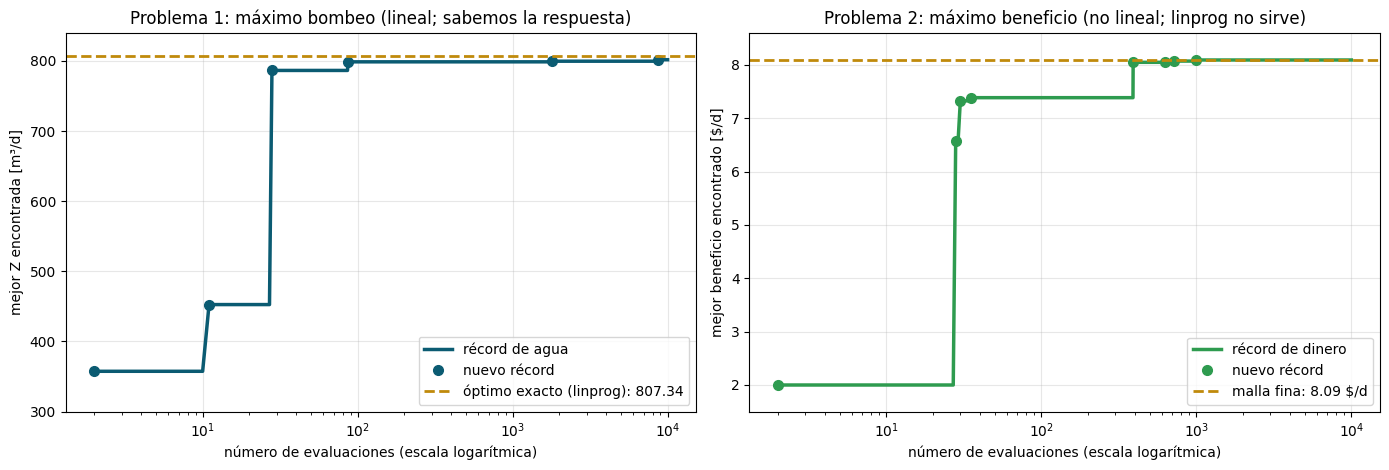

In [48]:
# Cómo avanza la búsqueda al azar: repasar las 10 000 decisiones en orden y anotar el récord después de cada una.
record_Z, record_B = [], []                       # el récord después de cada evaluación (uno por decisión probada)
mejoras_Z, mejoras_B = [], []                     # en qué evaluación se rompió el récord, y con cuánto
mejor_Z, mejor_B = -np.inf, -np.inf               # al principio no hay récord (menos infinito: cualquier valor lo supera)
cumplen = 0                                       # cuántas decisiones respetaron las reglas

for n, (p1_, p2_) in enumerate(probadas, start=1):    # n = número de evaluación: 1, 2, ..., 10 000
    if factible(p1_, p2_):                        # solo cuentan las que cumplen las reglas
        cumplen += 1
        Z_ = p1_ + p2_ + p3                       # su agua
        B_ = beneficio(p1_, p2_)                  # su dinero
        if Z_ > mejor_Z:                          # ¿nuevo récord de agua?
            mejor_Z = Z_
            mejoras_Z.append((n, Z_))
        if B_ > mejor_B:                          # ¿nuevo récord de dinero?
            mejor_B = B_
            mejoras_B.append((n, B_))
    record_Z.append(mejor_Z)                      # se anota el récord vigente, haya cambiado o no
    record_B.append(mejor_B)

print(f"de las {len(probadas)} decisiones, cumplieron las reglas {cumplen} ({cumplen / len(probadas):.0%})")
print("\nproblema 1, máximo bombeo: récords de agua (Z)")
for n, valor in mejoras_Z:
    print(f"  evaluación {n:5d}  →  Z = {valor:.2f} m³/d")
print("\nproblema 2, máximo beneficio: récords de dinero (B)")
for n, valor in mejoras_B:
    print(f"  evaluación {n:5d}  →  B = {valor:.2f} $/d")

n_eval = np.arange(1, len(probadas) + 1)          # 1, 2, ..., 10 000 (el eje horizontal)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
ax1.plot(n_eval, record_Z, lw=2.5, color="#0B5B72", label="récord de agua")
ax1.plot([n for n, v in mejoras_Z], [v for n, v in mejoras_Z], "o", ms=7, color="#0B5B72", label="nuevo récord")
ax1.axhline(Z_h, color="#c08a0b", ls="--", lw=2, label=f"óptimo exacto (linprog): {Z_h:.2f}")
ax1.set_xscale("log")                             # escala logarítmica: 1, 10, 100, 1 000, 10 000
ax1.set_ylim(300, 840)
ax1.set_xlabel("número de evaluaciones (escala logarítmica)")
ax1.set_ylabel("mejor Z encontrada [m³/d]")
ax1.set_title("Problema 1: máximo bombeo (lineal; sabemos la respuesta)")
ax1.legend(loc="lower right")
ax1.grid(alpha=0.3)

ax2.plot(n_eval, record_B, lw=2.5, color="#2e9b4f", label="récord de dinero")
ax2.plot([n for n, v in mejoras_B], [v for n, v in mejoras_B], "o", ms=7, color="#2e9b4f", label="nuevo récord")
ax2.axhline(B_malla[k], color="#c08a0b", ls="--", lw=2, label=f"malla fina: {B_malla[k]:.2f} $/d")
ax2.set_xscale("log")
ax2.set_ylim(1.5, 8.6)
ax2.set_xlabel("número de evaluaciones (escala logarítmica)")
ax2.set_ylabel("mejor beneficio encontrado [$/d]")
ax2.set_title("Problema 2: máximo beneficio (no lineal; linprog no sirve)")
ax2.legend(loc="lower right")
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Cómo leer las dos curvas.** El eje horizontal cuenta las evaluaciones, en **escala logarítmica**: cada marca vale diez veces la
anterior (1, 10, 100, 1 000, 10 000). Así caben en el mismo dibujo las primeras decisiones y las últimas. Cada **punto** es un
récord nuevo; cada tramo **plano** son evaluaciones que no mejoraron nada.

- **Al principio, mejora rápido.** En las primeras decenas de decisiones el récord salta varias veces: casi cualquier decisión que
  cumpla es mejor que la anterior.
- **Problema 1 (el examen): después, casi nada.** El récord llega a 798.66 m³/d en la evaluación 87 y solo vuelve a mejorar dos
  veces, poquito, en las 9 900 que siguen. Termina en 801.70: le faltan 5.64 m³/d para el óptimo exacto, **y no tiene manera de
  saberlo**. Aun con la respuesta a la vista, no la alcanza.
- **Problema 2 (el caso real): llega a la cima** (8.09 \$/d) hacia la evaluación 1 000, y las otras 9 000 ya no mejoran nada. Pero
  la búsqueda **no sabe** que ya llegó: lo sabemos nosotros porque hicimos la malla fina, algo que solo se puede con dos variables.
- **Desperdicia casi todo:** de cada 10 decisiones al azar, 9 no cumplen las reglas y se tiran sin aportar nada.

**La lección.** A la búsqueda al azar le da igual que el objetivo sea lineal o no: solo propone y califica, y por eso sirve para el
problema 2. Pero el problema 1 muestra su precio: no da garantía. Se detiene cuando se acaba el presupuesto de evaluaciones, no cuando llega al
óptimo. Por eso se mide con curvas como estas y se compara contra una referencia. El martes, el enjambre de partículas hará lo mismo,
pero aprendiendo de sus aciertos: su curva debería subir más rápido y gastar menos evaluaciones.

### 10.5 El beneficio en 3-D (gíralo con el mouse)

La superficie del beneficio sobre la región factible. Acerca, gira y pasa el mouse: el máximo es una **cima** dentro de la región, no una esquina.

In [49]:
# La superficie del beneficio en 3-D (se puede girar con el ratón).
import plotly.graph_objects as go
import plotly.io as pio
pio.renderers.default = "plotly_mimetype"         # el que dibuja VS Code (y JupyterLab)

sup = go.Surface(x=g, y=g, z=B_plano, colorscale="Viridis", colorbar=dict(title="$/d"),   # la superficie: altura = beneficio
                 hovertemplate="p1 = %{x:.0f}<br>p2 = %{y:.0f}<br>beneficio = %{z:.2f} $/d<extra></extra>")   # lo que aparece al pasar el ratón
cima = go.Scatter3d(x=[X[k, 0]], y=[X[k, 1]], z=[B_malla[k] + 0.15], mode="markers+text", text=["la cima"],
                    marker=dict(size=7, color="#f2c230", line=dict(color="black", width=1)))   # un punto en la cima (la mejor de la malla)
fig3d = go.Figure([sup, cima])
fig3d.update_layout(title="Fritz paga la luz: la superficie del beneficio", height=560,
                    scene=dict(xaxis_title="p1 [m³/d]", yaxis_title="p2 [m³/d]", zaxis_title="beneficio [$/d]",
                               xaxis_range=[0, 700], yaxis_range=[0, 500]))
fig3d.show()

Tres lecciones, que son el puente al martes:

1. **El óptimo dejó la esquina.** Con un objetivo no lineal puede quedar **dentro** de la región: el pozo 1 a unos 2.7 m y ninguna regla en su límite. La garantía
   de los vértices se pierde.
2. **La búsqueda al azar lo encontró** sin matriz, sin fórmula y sin `linprog`: solo proponiendo y calificando. Si en lugar de la matriz calificara con
   `hidra.simular`, funcionaría igual con un acuífero libre, transitorio o con transporte.
3. **Pero es ciega y cara:** gastó 10 000 evaluaciones, nueve de cada diez cayeron fuera de las reglas, y nunca sabe si ya llegó. El martes, el **enjambre de
   partículas** hace lo mismo con inteligencia: cada partícula aprende de su mejor hallazgo y del mejor del grupo.

<div style="border-left: 5px solid #54696F; padding: 6px 12px; background: rgba(127,127,127,0.08);">✔ <b>Punto de control.</b> la búsqueda al azar encontró un beneficio de unos 8.09 $/d cerca de (336, 34) m³/d, sin garantía. → Siguiente: <a href="#s11">11 · Cierre y tarea</a></div>

<hr style="border: none; border-top: 4px solid #54696F; margin: 28px 0 4px 0;">
<p style="color:#54696F; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 11 · CIERRE</p>

<a id="s11"></a>

## 11 · Cierre: por qué funcionó, y qué viene (2 min)

<span style="color:#54696F">**⏱ 2 min · 🏫 en clase**</span>

### 11.1 Por qué funcionó

Todo lo de hoy colgó de una sola palabra: **lineal**.

- La ecuación de flujo era lineal → valía la superposición → el simulador cabía en 12 números.
- Las restricciones eran lineales → la región factible era un polígono → el óptimo estaba en un vértice → `linprog` lo encontró **con garantía**.
- El objetivo también era lineal (el bombeo total). Con el costo de la energía (sección 10) dejó de serlo, el óptimo salió de la esquina y `linprog`
  ya no sirvió: la búsqueda al azar sí, pero sin garantía.

Ahora pregúntate qué pasa si el acuífero es libre (el espesor saturado cambia con el bombeo), si el régimen es transitorio, si el
objetivo involucra transporte de contaminantes o la zona de captura, o si el simulador es una caja negra que solo devuelve números.
En todos esos casos la matriz deja de existir y `linprog` no tiene nada que resolver. **Para eso están las metaheurísticas**,
y empezamos el martes con el enjambre de partículas, que volverá a este mismo acuífero y se medirá contra los 969.92 m³/d de hoy.

### 11.2 Trabajo asíncrono (1 h) y Tarea 1

1. **La Tarea 1 es el primero de los cuatro cuadernos de evaluación del curso.** Se aprueba con 6 de 10; con 2 de los 4 cuadernos de tarea aprobados, el examen del curso está aprobado. Abre `Tarea_1_estudiante.ipynb` (en esta misma carpeta), escribe tu correo de inscripción
   y sigue sus cinco etapas: es el problema de hoy con **tus** datos (tu límite de humedal y tu contrato del pozo 3). Cada etapa trae su comprobación
   inmediata (`grader.check`). Unos 60 minutos. Guárdala como `Tarea_1_<tu nombre>.ipynb` y súbela al formulario del curso **antes del martes 10 de noviembre**.
2. Si Python todavía te cuesta, repasa el tutorial de Python y NumPy del curso (`Información/complementos/1_python_numpy_tutorial_ESP.ipynb`), al menos las secciones
   de listas, NumPy y Matplotlib. No se califica, pero la Tarea 1 lo da por sabido.
3. **Antes del martes 10**, haz el Apéndice A de este cuaderno (la caja de herramientas, unos 25 minutos): trae todo el Python que usan las sesiones 2 a 4.
4. Si quieres practicar antes de la tarea: vuelve a resolver la sección 8 con el límite del humedal en 1.0 m y en 1.5 m, y mira qué restricciones quedan activas.

### 11.3 Referencias

- Peralta, R. C. (2012). *Groundwater Optimization Handbook: Flow, Contaminant Transport, and Conjunctive Management*. CRC Press. (El ejemplo clásico de los tres pozos.)
- Rodríguez-Pretelín, A. y Nowak, W. (2018). Integrating transient behavior as a new dimension to WHPA delineation. *Advances in Water Resources*, 119, 178–187. (El simulador rrwpt.)
- Ahlfeld, D. P. y Mulligan, A. E. (2000). *Optimal Management of Flow in Groundwater Systems*. Academic Press. (Matrices de respuesta y programación lineal en aguas subterráneas.)

<div style="background:#8A9AAB; color:white; padding:14px 18px; border-radius:6px; margin-top:36px;"><span style="font-size:1.4em; font-weight:bold;">APÉNDICE</span><br><span style="opacity:0.9;">🏠 en casa · 25 min</span></div>

<hr style="border: none; border-top: 4px solid #8A9AAB; margin: 28px 0 4px 0;">
<p style="color:#8A9AAB; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">APÉNDICE A · CAJA DE HERRAMIENTAS</p>

<a id="sA"></a>

## A · Caja de herramientas para las sesiones 2 a 4 (en casa, 25 min)

<span style="color:#8A9AAB">**⏱ 25 min · 🏠 en casa, antes del martes 10 · Todo el Python que usan las sesiones 2 a 4.**</span>

Los cuadernos del enjambre (sesión 2), de varios objetivos (sesión 3) y de la robustez (sesión 4) usan ocho herramientas más de Python.
Están aquí, con la misma matriz inventada de arriba, para que el martes 10 ninguna línea de código sea nueva.

| | Herramienta | Dónde la vuelves a ver |
|---|---|---|
| a | `if`, `elif`, `else`, `and`, `or` | S2: ¿mejoró la partícula su récord? · S3: ¿la decisión rompe una regla? |
| b | diccionarios `{'clave': valor}` | S2: el problema y cada partícula · S3: los resultados · S4: los parámetros de OMOPSO |
| c | funciones con argumentos por nombre, dos resultados y `lambda` | S2–S4: `pso.PSO(problema, MaxIter=200)`, `CostFunction=lambda x: ...` |
| d | listas por comprensión y `append` | S2: el historial del enjambre · S3: el frente como arreglo |
| e | azar reproducible con semilla | S2: el enjambre arranca al azar · S4: las muestras de la incertidumbre |
| f | resumir muchos resultados: máscaras, `mean`, `percentile`, `argmax` | S3: filtrar soluciones · S4: media, peor caso y riesgo |
| g | gráficas de varios paneles, `scatter` e histogramas | S3: los frentes de Pareto · S4: comparar decisiones |
| h | objetos con punto, medir el tiempo y dar formato a los números | S3 y S4: cuánto tarda OMOPSO; todas las tablas |

### A.1 Decidir: `if`, `elif`, `else`

Lo que está desplazado a la derecha solo se ejecuta si la condición es verdadera. `and` y `or` juntan condiciones.

In [50]:
# if / elif / else: hacer una cosa u otra según una condición.
s_pozo = 3.4                                   # abatimiento de un pozo [m]
if s_pozo > 3.0:
    print("INFACTIBLE: el pozo pasa de 3 m")
elif s_pozo > 2.8:                             # elif: solo se revisa si lo de arriba fue falso
    print("factible, pero casi en el límite")
else:                                          # else: si nada de lo anterior se cumplió
    print("factible con holgura")

q = np.array([300, 300, 300])
s_q = alpha @ q
if (s_q > 3.0).any() or fila_humedal @ q > 1.25:       # ¿algún pozo pasa de 3 m, o el humedal de 1.25 m?
    print("la decisión", q, "rompe alguna regla")

INFACTIBLE: el pozo pasa de 3 m
la decisión [300 300 300] rompe alguna regla


✏️ **Inténtalo:** cambia `s_pozo` a 2.9 y luego a 2.0. ¿Qué rama se ejecuta en cada caso?

### A.2 Diccionarios: datos con nombre

Una lista guarda valores por posición; un **diccionario** los guarda por nombre. Así se describe un problema de optimización en las
sesiones 2 a 4, y así guarda el enjambre cada partícula.

In [51]:
# Diccionarios: valores guardados con nombre (clave → valor). Así se configura el enjambre en la sesión 2.
problema = {'CostFunction': None, 'nVar': 2, 'VarMin': 0, 'VarMax': 1000}
print(problema['nVar'], problema['VarMax'])    # se pide por nombre

problema['VarMax'] = 800                       # cambiar un valor
for clave, valor in problema.items():          # recorrer nombre y valor
    print(f"{clave:12s} → {valor}")

otro = dict(problema, nVar=3)                  # una copia con un cambio; el original no se toca
print(otro['nVar'], problema['nVar'])

enjambre = [{'position': np.array([300., 150.]), 'cost': -750.0},      # una lista de diccionarios:
            {'position': np.array([200., 400.]), 'cost': -600.0}]      # una partícula por renglón
print(enjambre[1]['position'], enjambre[1]['cost'])                    # la segunda partícula: primero la lista, luego la clave

2 1000
CostFunction → None
nVar         → 2
VarMin       → 0
VarMax       → 800
3 2
[200. 400.] -600.0


✏️ **Inténtalo:** agrega a `problema` la clave `'nPop'` con el valor 30 y muéstrala.

### A.3 Funciones: argumentos por nombre, dos resultados y `lambda`

Un argumento puede traer un **valor por defecto** y pasarse **por nombre**. Una función puede devolver **dos cosas**, que se
desempacan con una coma. Y `lambda` escribe una función de una sola línea, útil para **pasarle una función a otra función**: así le
diremos al enjambre qué tiene que optimizar.

In [52]:
# Funciones con más opciones: devolver dos cosas, valores por omisión y funciones que reciben funciones.
def abatimiento(q, matriz=alpha, limite=3.0):  # matriz y limite tienen valor por omisión: si no se dan, se usan esos
    s = matriz @ q
    return s, (s <= limite).all()              # devuelve dos cosas

s_q, cumple = abatimiento(np.array([300, 300, 300]))          # se desempacan
print(np.round(s_q, 2), cumple)
print(abatimiento(np.array([300, 300, 300]), limite=2.7)[1])  # el mismo cálculo con otro límite, pasado por nombre

total = lambda q: q.sum()                      # una función de una línea

def mejor_de(funcion, candidatos):             # una función que recibe otra función
    valores = [funcion(c) for c in candidatos]   # califica a cada candidato con la función recibida
    return candidatos[int(np.argmax(valores))]   # y devuelve el de mayor valor

print(mejor_de(total, [np.array([300, 150, 300]), np.array([200, 400, 300])]))

[2.69 2.75 2.76] True
False
[200 400 300]


En la sesión 2 verás exactamente esto: `gbest, pop = pso.PSO(problema, MaxIter=200, PopSize=50)` (dos resultados, argumentos por
nombre) y `dict(problema, CostFunction=lambda x: ...)` (un diccionario con una función adentro).

✏️ **Inténtalo:** escribe `promedio = lambda q: q.mean()` y úsala con `mejor_de`. ¿Elige la misma decisión que `total`?

### A.4 Listas por comprensión y acumular con `append`

`[expresión for x in lista]` construye una lista nueva en una línea. `append` agrega al final de una lista: así se guarda el
**historial** de un algoritmo, iteración por iteración. `np.inf` es «infinito»: cualquier número lo mejora.

In [53]:
# Listas por comprensión y un récord que se actualiza en un ciclo.
bombeos = [100, 200, 300, 400, 500]
s_p1 = np.array([alpha[0, 0] * b for b in bombeos])          # el abatimiento del pozo 1 con cada bombeo
print(np.round(s_p1, 2))

historial, record = [], -np.inf                # el récord empieza en menos infinito: cualquier valor lo supera
for b in [300, 120, 450, 410, 200]:            # cinco propuestas, en orden
    if alpha[0, 0] * b <= 3.0 and b > record:  # factible y mejor que el récord
        record = b
    historial.append(record)                   # se anota el récord después de cada propuesta
print(historial)                               # el récord después de cada propuesta

[0.68 1.36 2.03 2.71 3.39]
[300, 300, 300, 410, 410]


✏️ **Inténtalo:** ¿por qué la propuesta 450 no cambió el récord? Compruébalo con `alpha[0, 0] * 450`.

### A.5 Azar reproducible: la semilla

Los métodos de las sesiones 2 a 4 usan números al azar. Con una **semilla** fija, todos obtenemos los mismos números y los
resultados se pueden repetir y comparar.

In [54]:
# Números al azar repetibles: la semilla hace que salgan siempre los mismos.
np.random.seed(0)                              # la semilla
print(np.random.uniform(0, 1000, 3))           # tres bombeos al azar entre 0 y 1000
np.random.seed(0)
print(np.random.uniform(0, 1000, 3))           # los mismos tres

rng = np.random.default_rng(1)                 # la forma moderna: un generador propio
print(np.round(rng.normal(0, 0.5, 5), 3))      # cinco números de una normal con media 0 y desviación 0.5

[548.813504 715.189366 602.763376]
[548.813504 715.189366 602.763376]
[ 0.173  0.411  0.165 -0.652  0.453]


✏️ **Inténtalo:** borra las dos líneas `np.random.seed(0)` y ejecuta la celda dos veces. ¿Qué cambia?

### A.6 Resumir muchos resultados: máscaras, `mean`, `percentile`, `argmax`

Con miles de decisiones (o de geologías) no se mira una por una: se **filtra** con una máscara de verdaderos y falsos y se
**resume**. `axis=1` opera a lo largo de cada fila; `axis=0`, a lo largo de cada columna.

In [55]:
# Evaluar muchas decisiones a la vez con matrices, sin ciclos.
rng = np.random.default_rng(2)
Q = rng.uniform(0, 600, size=(1000, 3))        # 1 000 decisiones al azar, una por fila
S = Q @ alpha.T                                # sus abatimientos: 1 000 filas, 3 columnas
factible = (S <= 3.0).all(axis=1)              # la máscara: True en las filas que cumplen todo
Z = Q.sum(axis=1)                              # el bombeo total de cada decisión

print(factible.sum(), "de", len(Q), "son factibles")
print("fracción que rompe alguna regla:", (~factible).mean())   # ~ invierte la máscara: True en las que no cumplen
mejor = np.argmax(np.where(factible, Z, -np.inf))          # la mejor entre las factibles
print("la mejor factible:", np.round(Q[mejor]), "con Z =", round(Z[mejor], 1))
print("Z de las factibles: media", round(Z[factible].mean(), 1), "· percentil 10:", round(np.percentile(Z[factible], 10), 1))
print("abatimiento medio por pozo:", np.round(S.mean(axis=0), 2))   # axis=0: el promedio de cada columna (cada pozo)

230 de 1000 son factibles
fracción que rompe alguna regla: 0.77
la mejor factible: [333. 236. 328.] con Z = 896.3
Z de las factibles: media 539.9 · percentil 10: 331.5
abatimiento medio por pozo: [2.7  2.76 2.79]


La «fracción que rompe alguna regla» es, con otro nombre, el **riesgo** de la sesión 4; el percentil 10 es un «peor caso».

✏️ **Inténtalo:** cambia el límite a 2.5 m. ¿Cuántas decisiones quedan factibles?

### A.7 Gráficas de varios paneles

`plt.subplots(1, 2)` crea dos paneles lado a lado; cada uno se dibuja por separado. `scatter` dibuja puntos e `hist` un histograma.

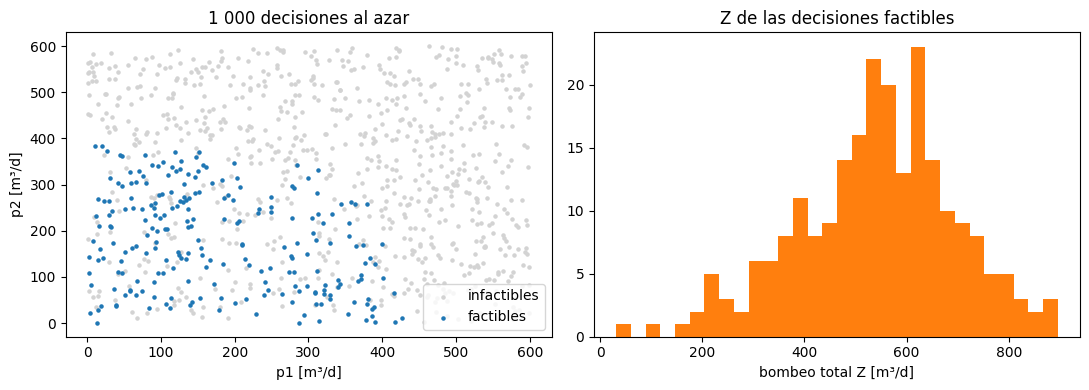

In [56]:
# Dos gráficas en una figura: las decisiones en el plano y el histograma de su bombeo total.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.scatter(Q[~factible, 0], Q[~factible, 1], s=5, color="lightgray", label="infactibles")   # Q[máscara, columna]: solo las filas elegidas
ax1.scatter(Q[factible, 0], Q[factible, 1], s=5, color="tab:blue", label="factibles")
ax1.set_xlabel("p1 [m³/d]"); ax1.set_ylabel("p2 [m³/d]"); ax1.set_title("1 000 decisiones al azar"); ax1.legend()
ax2.hist(Z[factible], bins=30, color="tab:orange")   # histograma: cuántas decisiones caen en cada intervalo de Z
ax2.set_xlabel("bombeo total Z [m³/d]"); ax2.set_title("Z de las decisiones factibles")
plt.tight_layout(); plt.show()

### A.8 Objetos, tiempo y formato

Un arreglo de NumPy (y el `Resultado` de hidra que verás enseguida) es un **objeto**: guarda datos y sabe hacer cosas, y ambas se
piden con un punto. `time.time()` mide cuánto tarda algo. Dentro de una `f"..."`, lo que va después de `:` da formato al número.

In [57]:
# Medir tiempos, atributos contra métodos y formato de números.
import time

t0 = time.time()                               # la hora al empezar, en segundos
S_grande = rng.uniform(0, 600, size=(200_000, 3)) @ alpha.T
print(f"200 000 decisiones evaluadas en {time.time() - t0:.3f} s")

print(Q.shape, Q.ndim)                         # datos del objeto: sin paréntesis
print(np.round(Q.max(axis=0)))                 # cosas que sabe hacer: con paréntesis

print(f"{807.3412:.2f} m³/d | {0.0712:.1%} | {'pozo 1':>8s} |")    # dos decimales, porcentaje, texto alineado

200 000 decisiones evaluadas en 0.002 s
(1000, 3) 2
[600. 600. 600.]
807.34 m³/d | 7.1% |   pozo 1 |


✏️ **Inténtalo:** imprime `0.1234` como porcentaje sin decimales (`:.0%`) y `969.92` con un decimal.

Con este apéndice completo tienes todo el Python del curso. Lo que aparezca de nuevo en las sesiones 2 a 4 (los métodos `pso.PSO`
y `OMOPSO`) se explicará ahí mismo.